# Experiment 4 — Speaker-change detection under speech variation

Frozen ECAPA-TDNN and WavLM representations are tested on constructed ASCEND and RAVDESS sequences containing speaker changes and within-speaker variation.


In [1]:
%pip -q install torch==2.6.0 torchaudio==2.6.0 torchvision==0.21.0 numpy==2.2.6 transformers==4.51.3 speechbrain==1.0.3 huggingface_hub==0.30.2 librosa==0.11.0 numba==0.61.2 soundfile==0.13.1 pyarrow==19.0.1 pandas==2.2.3 scikit-learn==1.6.1 scipy==1.15.3 matplotlib==3.10.3 tqdm==4.67.1 tabulate==0.9.0
%pip -q install --no-deps numpy==2.2.6 numba==0.61.2


## Environment and data storage

Install dependencies and connect to the datasets.


In [2]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Experiment configuration

Dataset paths, speaker partitions, scoring windows, and evaluation settings.


In [3]:
import os, sys, json, io, re, random, hashlib, zipfile, warnings, platform, subprocess, importlib.metadata, gc
from pathlib import Path
from collections import Counter
import numpy as np
installed_numpy = importlib.metadata.version("numpy")
installed_numba = importlib.metadata.version("numba")

if (
    np.__version__ != "2.2.6"
    or installed_numpy != "2.2.6"
    or installed_numba != "0.61.2"
):
    raise RuntimeError(
        f"Loaded NumPy={np.__version__}; "
        f"installed NumPy={installed_numpy}; Numba={installed_numba}. "
        "Re-run setup, restart the Colab session, "
        "then continue at section 2."
    )
import pandas as pd
import torch
import torchaudio
import librosa
import soundfile as sf
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import roc_auc_score
from tqdm.auto import tqdm
from huggingface_hub import model_info
SMOKE_TEST = False
CFG = dict(seed=2026, smoke=SMOKE_TEST, ascend='/content/drive/MyDrive/ASCEND', ravdess='/content/drive/MyDrive/RAVDESS', sr=16000, min_duration=2.2, max_duration=30., min_active_fraction=.15, active_db=-40., train_fraction=.5, dev_fraction=.25, min_speakers=6, max_per_speaker=40 if SMOKE_TEST else 400, pairs_per_condition=3 if SMOKE_TEST else 60, multi_turn_per_split=2 if SMOKE_TEST else 15, nojoin_per_split=2 if SMOKE_TEST else 30, crop_seconds=3., fade_seconds=.005, gap_seconds=0., contexts=[.75,1.0] if SMOKE_TEST else [.5,1.,1.5], hop=.20, min_separation=.6, tolerances=[.25,.5], selection_tolerance=.5, dev_fa_per_minute=2., batch_size=2, min_fusion_train_speakers=6, bootstrap=100 if SMOKE_TEST else 1000, wavlm='microsoft/wavlm-large', ecapa='speechbrain/spkrec-ecapa-voxceleb', wavlm_revision='main', ecapa_revision='main')
random.seed(CFG['seed']); np.random.seed(CFG['seed']); torch.manual_seed(CFG['seed'])
if torch.cuda.is_available(): torch.cuda.manual_seed_all(CFG['seed'])
torch.backends.cudnn.benchmark=False
torch.backends.cudnn.deterministic=True
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
if DEVICE=='cpu': warnings.warn('CPU inference is supported but WavLM Large will be slow; select a Colab GPU.')
def fingerprint(x): return hashlib.sha256(json.dumps(x,sort_keys=True,default=str).encode()).hexdigest()[:20]
ROOT=Path('/content/drive/MyDrive/Experiment_4_Results')
OUT=ROOT / ('smoke' if SMOKE_TEST else 'full') / fingerprint(CFG)
for sub in ['', 'embeddings','sequences','figures','audio']: (OUT/sub).mkdir(parents=True,exist_ok=True)
def save_json(path,x):
    tmp=Path(str(path)+'.tmp'); tmp.write_text(json.dumps(x,indent=2,default=str)); tmp.replace(path)
save_json(OUT/'config.json',CFG)
ENV={'python':sys.version,'platform':platform.platform(),'device':DEVICE,'torch':torch.__version__,'torchaudio':torchaudio.__version__,'packages':{p:importlib.metadata.version(p) for p in ['transformers','speechbrain','huggingface_hub','numpy','pandas','scipy','pyarrow','librosa','soundfile','scikit-learn']}}
save_json(OUT/'environment.json',ENV)
DIAGNOSTICS=[]
def note(message):
    DIAGNOSTICS.append(str(message)); print(message)
    save_json(OUT/'diagnostics.json',DIAGNOSTICS)
print('Outputs:',OUT)
print('GPU:',torch.cuda.get_device_name(0) if DEVICE=='cuda' else 'none')


Outputs: /content/drive/MyDrive/Experiment_4_Results/full/cf61e798b8ae007742d4
GPU: NVIDIA L4


## ASCEND corpus

Read bilingual speech recordings and language/speaker metadata.


In [4]:
RAW=[]
asc_root=Path(CFG['ascend'])
readmes=list(asc_root.rglob('README*'))
for p in readmes[:3]:
    text=p.read_text(errors='replace'); print(str(p), '\n',text[:18000]); save_json(OUT/('ascend_readme_'+fingerprint(str(p))+'.json'),{'path':str(p),'text':text})
shards=sorted(asc_root.rglob('*.parquet'))
if not shards: note('ASCEND: no Parquet files discovered.')
SCHEMAS={}
for p in shards:
    schema=pq.ParquetFile(p).schema_arrow
    SCHEMAS[str(p)]=str(schema); print(p.name, schema)
    required={'original_speaker_id','language','audio'}
    if not required.issubset(schema.names):
        note(f'Unsupported ASCEND schema: {p}: missing {required-set(schema.names)}'); continue
    for batch in pq.ParquetFile(p).iter_batches(batch_size=64):
        for row in batch.to_pylist():
            idx=sum(1 for _ in []) if False else len(RAW)
            RAW.append(dict(dataset='ASCEND',speaker=row.get('original_speaker_id'),language=str(row.get('language','')).lower(),emotion='',session=str(row.get('session_id','unknown')),source=str(p),locator=idx,audio=row['audio'],reported_duration=row.get('duration')))
save_json(OUT/'ascend_schemas.json',SCHEMAS)
print('ASCEND rows:',len(RAW))


/content/drive/MyDrive/ASCEND/README.md 
 ---
annotations_creators:
- expert-generated
language_creators:
- crowdsourced
language:
- en
- zh
license:
- cc-by-sa-4.0
multilinguality:
- multilingual
size_categories:
- 10K<n<100K
source_datasets:
- original
task_categories:
- automatic-speech-recognition
task_ids: []
pretty_name: 'ASCEND: A Spontaneous Chinese-English Dataset for Code-switching in
  Multi-turn Conversation'
tags:
- speech-recognition
- code-switching
dataset_info:
  config_name: main
  features:
  - name: id
    dtype: string
  - name: path
    dtype: string
  - name: audio
    dtype:
      audio:
        sampling_rate: 16000
  - name: transcription
    dtype: string
  - name: duration
    dtype: float32
  - name: language
    dtype: string
  - name: original_speaker_id
    dtype: int64
  - name: session_id
    dtype: int64
  - name: topic
    dtype: string
  splits:
  - name: train
    num_bytes: 1014573740.14
    num_examples: 9869
  - name: test
    num_bytes: 10617123

## RAVDESS corpus

Read speech recordings and extract actor and emotion labels.


In [5]:
EMOTIONS={'01':'neutral','02':'calm','03':'happy','04':'sad','05':'angry','06':'fearful','07':'disgusted','08':'surprised'}
RAV_RE=re.compile(r'^(\d{2})-(\d{2})-(\d{2})-(\d{2})-(\d{2})-(\d{2})-(\d{2})$')
def rav_row(source,member=None):
    name=Path(member or source).stem; match=RAV_RE.match(name)
    row=dict(dataset='RAVDESS',speaker=None,language='',emotion='',session='unknown',source=str(source),locator=member or '',audio=None)
    if not match: row['discovery_error']='malformed_ravdess_filename'; return row
    mod,channel,emo,intensity,statement,rep,actor=match.groups()
    if mod!='03' or channel!='01': row['discovery_error']='excluded_non_audio_speech'; return row
    if emo not in EMOTIONS or not 1<=int(actor)<=24: row['discovery_error']='invalid_ravdess_labels'; return row
    row.update(speaker=actor,language='en',emotion=EMOTIONS[emo],intensity=intensity,statement=statement,repetition=rep)
    return row
for p in sorted(Path(CFG['ravdess']).rglob('*')):
    if p.suffix.lower() in {'.wav','.flac'}: RAW.append(rav_row(p))
    elif p.suffix.lower()=='.zip':
        try:
            with zipfile.ZipFile(p) as z:
                for m in sorted(z.namelist()):
                    if Path(m).suffix.lower() in {'.wav','.flac'}: RAW.append(rav_row(p,m))
        except Exception as e: note(f'ZIP discovery failed {p}: {e}')
print('Discovered entries by dataset:',Counter(r['dataset'] for r in RAW))


Discovered entries by dataset: Counter({'ASCEND': 12314, 'RAVDESS': 1462})


## Audio preparation and dataset splits

Validate and filter recordings, then create speaker-disjoint partitions.


In [6]:
def decode_row(r):
    a=r['audio']
    if r['dataset']=='RAVDESS':
        if r['locator']:
            with zipfile.ZipFile(r['source']) as z: data=io.BytesIO(z.read(r['locator']))
        else: data=r['source']
        y,sr=sf.read(data,dtype='float32',always_2d=True)
    elif isinstance(a,dict) and a.get('bytes') is not None:
        y,sr=sf.read(io.BytesIO(a['bytes']),dtype='float32',always_2d=True)
    elif isinstance(a,dict) and a.get('array') is not None:
        y=np.asarray(a['array'],dtype=np.float32); sr=int(a['sampling_rate'])
        if y.ndim==1: y=y[:,None]
    else:
        path=a.get('path') if isinstance(a,dict) else a
        if not path: raise ValueError('audio lacks bytes, array, or path')
        path=Path(path)
        if not path.is_absolute(): path=Path(r['source']).parent/path
        y,sr=sf.read(path,dtype='float32',always_2d=True)
    if y.ndim!=2 or not y.size or not np.isfinite(y).all(): raise ValueError('invalid samples')
    y=y.mean(axis=1)
    if sr!=CFG['sr']: y=librosa.resample(y,orig_sr=sr,target_sr=CFG['sr'])
    return y.astype(np.float32)
AUDIT=[]
for r in tqdm(RAW,desc='Decode and audit'):
    item={k:v for k,v in r.items() if k!='audio'}; item['status']='usable'
    try:
        if r.get('discovery_error'): raise ValueError(r['discovery_error'])
        if r['speaker'] is None or str(r['speaker']).strip().lower() in {'','none','nan'}: raise ValueError('missing_speaker')
        if r['dataset']=='ASCEND' and r['language'] not in {'en','zh','mixed'}: raise ValueError('unsupported_language')
        y=decode_row(r); duration=len(y)/CFG['sr']
        item['duration']=duration
        if not CFG['min_duration']<=duration<=CFG['max_duration']: raise ValueError('duration_filter')
        frames=librosa.feature.rms(y=y,frame_length=400,hop_length=160)[0]
        item['active_fraction']=float(np.mean(frames>10**(CFG['active_db']/20)))
        if item['active_fraction']<CFG['min_active_fraction']: raise ValueError('silence_filter')
        pcm=np.round(np.clip(y,-1,1)*32767).astype('<i2')
        digest=hashlib.sha256(pcm.tobytes()).hexdigest()
        item.update(recording=digest,speaker=r['dataset']+':'+str(r['speaker']))
        dest=OUT/'audio'/f'{digest}.wav'
        if not dest.exists(): sf.write(dest,y,CFG['sr'],subtype='FLOAT')
        item['path']=str(dest)
    except Exception as e: item['status']=str(e)
    AUDIT.append(item)
del RAW; gc.collect()
audit=pd.DataFrame(AUDIT)
if audit.empty: raise RuntimeError('No entries found. Check dataset paths and discovery diagnostics.')
if 'recording' not in audit: raise RuntimeError('No decodable eligible recordings; inspect displayed schemas and paths.')
good=audit[audit.status=='usable']
conflicts=good.groupby('recording').speaker.nunique(); conflicts=set(conflicts[conflicts>1].index)
audit.loc[audit.recording.isin(conflicts),'status']='duplicate_identity_conflict'
good=audit[audit.status=='usable']
audit.loc[good[good.duplicated('recording',keep='first')].index,'status']='duplicate_audio'
good=audit[audit.status=='usable'].sort_values(['speaker','recording'])
cap=good.groupby('speaker').cumcount()>=CFG['max_per_speaker']
audit.loc[good[cap].index,'status']='sampling_cap'
audit.to_csv(OUT/'dataset_audit.csv',index=False)
records=audit[audit.status=='usable'].copy().reset_index(drop=True)
summary=audit.groupby(['dataset','status']).size().rename('recordings').reset_index()
display(summary)
summary.to_csv(OUT/'audit_summary.csv',index=False)
for key in ['speaker','language','emotion']:
    table=records.groupby(['dataset',key],dropna=False).agg(recordings=('recording','size'),seconds=('duration','sum')).reset_index()
    table.to_csv(OUT/f'audit_by_{key}.csv',index=False); display(table)
display(records.groupby('dataset').duration.describe())
records.groupby('dataset').duration.describe().to_csv(OUT/'duration_distribution.csv')
PARTS=[]
for dataset,g in records.groupby('dataset'):
    speakers=np.array(sorted(g.speaker.unique())); rng=np.random.default_rng(CFG['seed']); rng.shuffle(speakers)
    if len(speakers)<CFG['min_speakers']:
        note(f'{dataset}: {len(speakers)} usable speakers; need {CFG["min_speakers"]}; evaluation skipped.'); continue
    n=len(speakers); nt=max(2,int(n*CFG['train_fraction'])); nd=max(2,int(n*CFG['dev_fraction']))
    nt=min(nt,n-4); nd=min(nd,n-nt-2)
    for i,s in enumerate(speakers): PARTS.append(dict(dataset=dataset,speaker=s,split='train' if i<nt else 'dev' if i<nt+nd else 'test'))
partitions=pd.DataFrame(PARTS,columns=['dataset','speaker','split'])
partitions.to_csv(OUT/'speaker_partitions.csv',index=False)
records=records.merge(partitions,on=['dataset','speaker'],how='inner',validate='many_to_one')
assert not partitions.speaker.duplicated().any()
assert records.groupby('recording').split.nunique().max()<=1 if len(records) else True
ELIG=[]
for (dataset,split,speaker),g in records.groupby(['dataset','split','speaker']):
    label='language' if dataset=='ASCEND' else 'emotion'
    counts=g.groupby(label).size().to_dict()
    ELIG.append(dict(dataset=dataset,split=split,speaker=speaker,recordings=len(g),same_condition=any(v>=2 for v in counts.values()),variation=len(counts)>=2,english_chinese={'en','zh'}.issubset(counts),neutral_angry={'neutral','angry'}.issubset(counts),labels=json.dumps(counts)))
eligibility=pd.DataFrame(ELIG); eligibility.to_csv(OUT/'condition_eligibility.csv',index=False); display(eligibility)
if records.empty: raise RuntimeError('No dataset supports speaker-disjoint evaluation. Audit files explain exclusions; add eligible data or revise documented filters.')


Decode and audit:   0%|          | 0/13776 [00:00<?, ?it/s]

,dataset,status,recordings
0,ASCEND,duration_filter,5425
1,ASCEND,sampling_cap,435
2,ASCEND,usable,6454
3,RAVDESS,malformed_ravdess_filename,22
4,RAVDESS,silence_filter,537
5,RAVDESS,usable,903


,dataset,speaker,recordings,seconds
0,ASCEND,ASCEND:1,400,1782.974062
1,ASCEND,ASCEND:10,392,1803.431500
2,ASCEND,ASCEND:11,254,1520.099000
3,ASCEND,ASCEND:12,306,1264.714062
4,ASCEND,ASCEND:13,232,989.289125
5,ASCEND,ASCEND:14,184,702.397687
6,ASCEND,ASCEND:15,285,1385.646313
7,ASCEND,ASCEND:16,400,1913.799313
8,ASCEND,ASCEND:17,281,1137.081062
9,ASCEND,ASCEND:18,221,756.542063


,dataset,language,recordings,seconds
0,ASCEND,en,1279,5046.218250
1,ASCEND,mixed,2572,13511.379188
2,ASCEND,zh,2603,10981.614625
3,RAVDESS,en,903,3377.526250


,dataset,emotion,recordings,seconds
0,ASCEND,,6454,29539.212062
1,RAVDESS,angry,180,699.502750
2,RAVDESS,calm,25,96.063125
3,RAVDESS,disgusted,122,493.729188
4,RAVDESS,fearful,160,576.812937
5,RAVDESS,happy,161,591.127000
6,RAVDESS,neutral,20,73.073313
7,RAVDESS,sad,85,319.153937
8,RAVDESS,surprised,150,528.064000


,count,mean,std,min,25%,50%,75%,max
dataset,,,,,,,,
ASCEND,6454.0,4.576884,2.177861,2.200000,2.950188,3.930219,5.567500,15.000000
RAVDESS,903.0,3.740339,0.334206,2.969625,3.503500,3.703750,3.903938,5.271937


,dataset,split,speaker,recordings,same_condition,variation,english_chinese,neutral_angry,labels
0,ASCEND,dev,ASCEND:11,254,True,True,True,False,"{""en"": 15, ""mixed"": 132, ""zh"": 107}"
1,ASCEND,dev,ASCEND:20,214,True,True,True,False,"{""en"": 36, ""mixed"": 55, ""zh"": 123}"
2,ASCEND,dev,ASCEND:26,318,True,True,True,False,"{""en"": 22, ""mixed"": 117, ""zh"": 179}"
3,ASCEND,dev,ASCEND:3,294,True,True,True,False,"{""en"": 10, ""mixed"": 198, ""zh"": 86}"
4,ASCEND,dev,ASCEND:4,265,True,True,True,False,"{""en"": 31, ""mixed"": 126, ""zh"": 108}"
5,ASCEND,test,ASCEND:13,232,True,True,True,False,"{""en"": 84, ""mixed"": 112, ""zh"": 36}"
6,ASCEND,test,ASCEND:14,184,True,True,True,False,"{""en"": 83, ""mixed"": 60, ""zh"": 41}"
7,ASCEND,test,ASCEND:16,400,True,True,True,False,"{""en"": 45, ""mixed"": 145, ""zh"": 210}"
8,ASCEND,test,ASCEND:17,281,True,True,True,False,"{""en"": 81, ""mixed"": 95, ""zh"": 105}"
9,ASCEND,test,ASCEND:19,361,True,True,True,False,"{""en"": 24, ""mixed"": 113, ""zh"": 224}"


In [7]:
display(
    audit.groupby(["dataset", "status"], dropna=False)
    .size()
    .rename("recordings")
    .reset_index()
)


,dataset,status,recordings
0,ASCEND,duration_filter,5425
1,ASCEND,sampling_cap,435
2,ASCEND,usable,6454
3,RAVDESS,malformed_ravdess_filename,22
4,RAVDESS,silence_filter,537
5,RAVDESS,usable,903


## Construct speech sequences

Concatenate selected clips and label genuine speaker changes and same-speaker joins.


In [8]:
def condition(a,b):
    same=a['speaker']==b['speaker']; ds=a['dataset']
    if ds=='ASCEND':
        changed=a['language']!=b['language']
        return ('same_speaker_language_change' if changed else 'same_condition_control') if same else ('genuine_cross_language' if changed else 'genuine_same_language')
    changed=a['emotion']!=b['emotion']
    return ('same_speaker_emotion_change' if changed else 'same_condition_control') if same else ('genuine_different_emotion' if changed else 'genuine_same_emotion')
def clip_audio(r):
    y,sr=sf.read(r['path'],dtype='float32'); assert sr==CFG['sr']
    n=min(len(y),round(CFG['crop_seconds']*sr)); start=(len(y)-n)//2; y=y[start:start+n].copy()
    rms=float(np.sqrt(np.mean(y*y)+1e-12)); y*=min(10.,10**(-25/20)/max(rms,1e-6))
    y=np.clip(y,-.99,.99); f=min(round(CFG['fade_seconds']*sr),len(y)//2)
    if f: y[:f]*=np.linspace(0,1,f); y[-f:]*=np.linspace(1,0,f)
    return y,start/sr
SEQS=[]; JOINS=[]; SEGMENTS=[]
def make_sequence(rows,split,nojoin=False):
    rid=[r['recording'] for r in rows]
    sid=fingerprint({'rows':rid,'split':split,'nojoin':nojoin,'preprocess':CFG})
    if any(s['sequence']==sid for s in SEQS): return False
    chunks=[]; segments=[]; joins=[]; cursor=0.; gap=np.zeros(round(CFG['gap_seconds']*CFG['sr']),np.float32)
    for i,r in enumerate(rows):
        y,offset=clip_audio(r)
        if i:
            t=cursor+len(gap)/CFG['sr']/2
            joins.append(dict(sequence=sid,time=t,is_change=rows[i-1]['speaker']!=r['speaker'],condition=condition(rows[i-1],r),left=rows[i-1]['speaker'],right=r['speaker']))
            chunks.append(gap); cursor+=len(gap)/CFG['sr']
        segments.append(dict(sequence=sid,recording=r['recording'],speaker=r['speaker'],start=cursor,end=cursor+len(y)/CFG['sr'],source_offset=offset,language=r['language'],emotion=r['emotion'],session=r['session']))
        chunks.append(y); cursor+=len(y)/CFG['sr']
    y=np.concatenate(chunks); path=OUT/'sequences'/f'{sid}.wav'
    if not path.exists(): sf.write(path,y,CFG['sr'],subtype='FLOAT')
    group='no_join_control' if nojoin else joins[0]['condition'] if len(joins)==1 else 'multi_turn'
    SEQS.append(dict(sequence=sid,dataset=rows[0]['dataset'],split=split,group=group,duration=cursor,path=str(path),speakers=json.dumps(sorted(set(r['speaker'] for r in rows))),recordings=json.dumps(rid),waveform_sha256=hashlib.sha256(y.tobytes()).hexdigest()))
    JOINS.extend(joins); SEGMENTS.extend(segments); return True
rng=np.random.default_rng(CFG['seed'])
for (dataset,split),g in records.groupby(['dataset','split']):
    rows=g.to_dict('records'); rows=[r for r in rows if dataset!='ASCEND' or r['language'] in {'en','zh'}]
    if len(rows)<2: note(f'{dataset}/{split}: insufficient en/zh or speech clips'); continue
    target=['genuine_same_language','genuine_cross_language','same_speaker_language_change','same_condition_control'] if dataset=='ASCEND' else ['genuine_same_emotion','genuine_different_emotion','same_speaker_emotion_change','same_condition_control']
    counts=Counter(); attempts=0; limit=max(5000,CFG['pairs_per_condition']*1000)
    while attempts<limit and any(counts[c]<CFG['pairs_per_condition'] for c in target):
        attempts+=1; i,j=rng.choice(len(rows),2,replace=False); a,b=rows[i],rows[j]; c=condition(a,b)
        if counts[c]<CFG['pairs_per_condition'] and make_sequence([a,b],split): counts[c]+=1
    for c in target:
        if counts[c]<CFG['pairs_per_condition']: note(f'{dataset}/{split}/{c}: constructed {counts[c]} of {CFG["pairs_per_condition"]}; bounded sampling or unavailable support.')
    for i in range(CFG['multi_turn_per_split']):
        chosen=rng.choice(len(rows),size=min(4,len(rows)),replace=False); make_sequence([rows[j] for j in chosen],split)
    for j in rng.choice(len(rows),size=min(len(rows),CFG['nojoin_per_split']),replace=False): make_sequence([rows[j]],split,True)
seqs=pd.DataFrame(SEQS)
joins=pd.DataFrame(JOINS,columns=['sequence','time','is_change','condition','left','right'])
segments=pd.DataFrame(SEGMENTS)
if seqs.empty: raise RuntimeError('No supported sequences. Inspect condition eligibility.')
seqs.to_csv(OUT/'sequence_metadata.csv',index=False)
joins.to_csv(OUT/'ground_truth_boundaries.csv',index=False)
segments.to_csv(OUT/'sequence_segments.csv',index=False)
assert segments.merge(seqs[['sequence','split']],on='sequence').groupby('recording').split.nunique().max()==1
assert seqs.groupby('waveform_sha256').split.nunique().max()==1
display(seqs.groupby(['dataset','split','group']).size().rename('n').reset_index())
note('ground_truth_boundaries.csv includes all joins with is_change flag; only is_change=True rows are reference speaker boundaries.')


,dataset,split,group,n
0,ASCEND,dev,genuine_cross_language,60
1,ASCEND,dev,genuine_same_language,60
2,ASCEND,dev,multi_turn,15
3,ASCEND,dev,no_join_control,30
4,ASCEND,dev,same_condition_control,60
5,ASCEND,dev,same_speaker_language_change,60
6,ASCEND,test,genuine_cross_language,60
7,ASCEND,test,genuine_same_language,60
8,ASCEND,test,multi_turn,15
9,ASCEND,test,no_join_control,30


ground_truth_boundaries.csv includes all joins with is_change flag; only is_change=True rows are reference speaker boundaries.


## Extract frozen representations

Compute cached ECAPA embeddings and representations from all 24 WavLM layers.


In [9]:
from transformers import AutoFeatureExtractor, WavLMModel
from speechbrain.inference.speaker import EncoderClassifier
REVISIONS={name:model_info(CFG[name],revision=CFG[name+'_revision']).sha for name in ['wavlm','ecapa']}
ENV['model_revisions']=REVISIONS; save_json(OUT/'environment.json',ENV)
def cache_paths(s,context,model):
    meta=dict(sequence=s['sequence'],waveform_sha256=s['waveform_sha256'],model=CFG[model],revision=REVISIONS[model],context=context,hop=CFG['hop'],sr=CFG['sr'],preprocessing=CFG,layers=list(range(1,25)) if model=='wavlm' else ['ecapa'])
    key=fingerprint(meta); return OUT/'embeddings'/f'{key}.npz',OUT/'embeddings'/f'{key}.json',meta
def windows(s,context):
    y,sr=sf.read(s['path'],dtype='float32'); n=round(context*sr); step=round(CFG['hop']*sr)
    starts=np.arange(0,len(y)-n+1,step,dtype=int)
    # Compare windows whose start indices differ by approximately one context.
    lag=max(1,round(n/step))
    return y,n,starts,lag
def extract_cache(model_name):
    pending=[(s,c) for s in seqs.to_dict('records') for c in CFG['contexts'] if not cache_paths(s,c,model_name)[0].exists()]
    if not pending: print(model_name,'all embeddings cached'); return
    if model_name=='wavlm':
        processor=AutoFeatureExtractor.from_pretrained(CFG['wavlm'],revision=REVISIONS['wavlm'])
        model=WavLMModel.from_pretrained(CFG['wavlm'],revision=REVISIONS['wavlm']).eval().to(DEVICE)
        assert model.config.num_hidden_layers==24
    else:
        model=EncoderClassifier.from_hparams(source=CFG['ecapa'],revision=REVISIONS['ecapa'],savedir=str(OUT/'embeddings'/'ecapa_model'/REVISIONS['ecapa']),run_opts={'device':DEVICE})
        model.eval()
    for p in model.parameters(): p.requires_grad_(False)
    for s,context in tqdm(pending,desc=model_name+' cache'):
        path,sidecar,meta=cache_paths(s,context,model_name); y,n,starts,lag=windows(s,context); all_emb=[]
        if len(starts)<=lag: note(f'Too short for paired windows: {s["sequence"]}/{context}'); continue
        for k in range(0,len(starts),CFG['batch_size']):
            waves=[y[a:a+n] for a in starts[k:k+CFG['batch_size']]]
            with torch.inference_mode():
                if model_name=='wavlm':
                    inputs=processor(waves,sampling_rate=CFG['sr'],return_tensors='pt',padding=True,return_attention_mask=True)
                    values=inputs.input_values.to(DEVICE); mask=inputs.attention_mask.to(DEVICE)
                    with torch.autocast(device_type=DEVICE,dtype=torch.float16,enabled=DEVICE=='cuda'):
                        states=model(values,attention_mask=mask,output_hidden_states=True).hidden_states
                    lengths=model._get_feat_extract_output_lengths(mask.sum(-1))
                    valid=torch.arange(states[1].shape[1],device=DEVICE)[None,:]<lengths[:,None]
                    emb=torch.stack([(h.float()*valid[:,:,None]).sum(1)/lengths[:,None] for h in states[1:25]],dim=1)
                    del states
                else:
                    values=torch.tensor(np.stack(waves),device=DEVICE); lengths=torch.ones(len(waves),device=DEVICE)
                    emb=model.encode_batch(values,wav_lens=lengths).float().reshape(len(waves),1,-1)
                emb=torch.nn.functional.normalize(emb,dim=-1); all_emb.append(emb.cpu().numpy().astype(np.float32))
        tmp=Path(str(path)+'.tmp')
        with tmp.open('wb') as f: np.savez_compressed(f,embeddings=np.concatenate(all_emb),starts=starts/CFG['sr'],duration=n/CFG['sr'],lag=lag)
        tmp.replace(path); save_json(sidecar,meta)
    del model
    gc.collect()
    if DEVICE=='cuda': torch.cuda.empty_cache()
extract_cache('wavlm')
extract_cache('ecapa')


DEBUG:speechbrain.utils.checkpoints:Registered checkpoint save hook for _speechbrain_save
DEBUG:speechbrain.utils.checkpoints:Registered checkpoint load hook for _speechbrain_load
DEBUG:speechbrain.utils.checkpoints:Registered checkpoint save hook for save
DEBUG:speechbrain.utils.checkpoints:Registered checkpoint load hook for load
DEBUG:speechbrain.utils.checkpoints:Registered checkpoint save hook for _save
DEBUG:speechbrain.utils.checkpoints:Registered checkpoint load hook for _recover
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warn

wavlm cache:   0%|          | 0/5130 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/nn/functional.py:5962: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  warnings.warn(


Too short for paired windows: c4501bbc72366e2bd7c3/1.5
Too short for paired windows: 83079b9b8bdf2edce090/1.5
Too short for paired windows: 01f21f093f6f140b27a7/1.5
Too short for paired windows: 9900762817bdf8d1463a/1.5
Too short for paired windows: c3ddb9357e355d4321bc/1.5
Too short for paired windows: a468372ed693791a6130/1.5
Too short for paired windows: 96de31a7a503fd63c64b/1.5
Too short for paired windows: 666b3b572c2f8d283fc0/1.5
Too short for paired windows: 863997d9c3c82e825fbe/1.5
Too short for paired windows: f430a8c0bf6315e06cab/1.5
Too short for paired windows: 683c95e2ce65d8307002/1.5
Too short for paired windows: fc3aafaff5d8d32e17f2/1.5
Too short for paired windows: 450078e528e7a475f723/1.5
Too short for paired windows: b89b7198c4c4e68bf74c/1.5
Too short for paired windows: d407bc37a006babed512/1.5
Too short for paired windows: 6f436712131a0b9cdaab/1.5
Too short for paired windows: d7a602244ed1e2b2edbb/1.5
Too short for paired windows: 0c913b4a9d6a302b24ae/1.5
Too short 

INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Fetching from HuggingFace Hub 'speechbrain/spkrec-ecapa-voxceleb' if not cached
DEBUG:speechbrain.utils.fetching:Fetch: Local file found, creating symlink '/root/.cache/huggingface/hub/models--speechbrain--spkrec-ecapa-voxceleb/snapshots/0f99f2d0ebe89ac095bcc5903c4dd8f72b367286/hyperparams.yaml' -> '/content/drive/MyDrive/Experiment_4_Results/full/cf61e798b8ae007742d4/embeddings/ecapa_model/0f99f2d0ebe89ac095bcc5903c4dd8f72b367286/hyperparams.yaml'
INFO:speechbrain.utils.fetching:Fetch custom.py: Fetching from HuggingFace Hub 'speechbrain/spkrec-ecapa-voxceleb' if not cached
DEBUG:speechbrain.utils.checkpoints:Registered checkpoint save hook for _save
DEBUG:speechbrain.utils.checkpoints:Registered checkpoint load hook for _load
DEBUG:speechbrain.utils.checkpoints:Registered parameter transfer hook for _load
/usr/local/lib/python3.13/dist-packages/speechbrain/utils/autocast.py:188: FutureWarning: `torch.cuda.amp.custom_fwd(args...)

ecapa cache:   0%|          | 0/5130 [00:00<?, ?it/s]

Too short for paired windows: c4501bbc72366e2bd7c3/1.5
Too short for paired windows: 83079b9b8bdf2edce090/1.5
Too short for paired windows: 01f21f093f6f140b27a7/1.5
Too short for paired windows: 9900762817bdf8d1463a/1.5
Too short for paired windows: c3ddb9357e355d4321bc/1.5
Too short for paired windows: a468372ed693791a6130/1.5
Too short for paired windows: 96de31a7a503fd63c64b/1.5
Too short for paired windows: 666b3b572c2f8d283fc0/1.5
Too short for paired windows: 863997d9c3c82e825fbe/1.5
Too short for paired windows: f430a8c0bf6315e06cab/1.5
Too short for paired windows: 683c95e2ce65d8307002/1.5
Too short for paired windows: fc3aafaff5d8d32e17f2/1.5
Too short for paired windows: 450078e528e7a475f723/1.5
Too short for paired windows: b89b7198c4c4e68bf74c/1.5
Too short for paired windows: d407bc37a006babed512/1.5
Too short for paired windows: 6f436712131a0b9cdaab/1.5
Too short for paired windows: d7a602244ed1e2b2edbb/1.5
Too short for paired windows: 0c913b4a9d6a302b24ae/1.5
Too short 

## Score and match speaker boundaries

Compute temporal cosine-distance scores, select peaks, and match them to reference changes.


In [10]:
SIGNALS={}
for s in tqdm(seqs.to_dict('records'),desc='Build audio-only score signals'):
    for context in CFG['contexts']:
        for model_name in ['wavlm','ecapa']:
            path,_,_=cache_paths(s,context,model_name)
            if not path.exists(): continue
            with np.load(path) as z:
                emb=z['embeddings']; starts=z['starts']; lag=int(z['lag']); width=float(z['duration'])
            scores=1-np.sum(emb[:-lag]*emb[lag:],axis=-1)
            times=(starts[:-lag]+starts[lag:]+width)/2
            SIGNALS[(s['sequence'],context,model_name)]=(times,np.clip(scores,0,2))
def predict(times,scores,threshold,separation=None):
    separation=CFG['min_separation'] if separation is None else separation
    if not len(scores): return np.array([])
    peaks=find_peaks(np.r_[-np.inf,scores,-np.inf],height=threshold)[0]-1
    accepted=[]
    for i in sorted(peaks,key=lambda i:(-scores[i],times[i])):
        if all(abs(times[i]-times[j])>=separation for j in accepted): accepted.append(i)
    return np.sort(times[accepted])
def match_boundaries(pred,ref,tol):
    pred=np.asarray(pred); ref=np.asarray(ref); n,m=len(pred),len(ref)
    if not n or not m: return [],list(range(n)),list(range(m))
    # Dummy cost exceeds all possible summed localization costs.
    penalty=(n+m+1)*(tol+1); cost=np.zeros((n+m,n+m))
    d=np.abs(pred[:,None]-ref[None,:]); cost[:n,:m]=np.where(d<=tol,d,4*penalty)
    cost[:n,m:]=penalty; cost[n:,:m]=penalty
    ii,jj=linear_sum_assignment(cost)
    pairs=[(int(i),int(j),float(d[i,j])) for i,j in zip(ii,jj) if i<n and j<m and d[i,j]<=tol]
    return pairs,[i for i in range(n) if i not in {a for a,b,e in pairs}],[j for j in range(m) if j not in {b for a,b,e in pairs}]
def counts_for(s,times,scores,threshold,tol):
    pred=predict(times,scores,threshold)
    ref=joins[(joins.sequence==s['sequence']) & joins.is_change].time.to_numpy(float)
    pairs,fp,fn=match_boundaries(pred,ref,tol)
    return dict(sequence=s['sequence'],dataset=s['dataset'],split=s['split'],group=s['group'],duration=s['duration'],tp=len(pairs),fp=len(fp),fn=len(fn),error_sum=sum(p[2] for p in pairs),errors=[p[2] for p in pairs]),pred,pairs
def aggregate(rows):
    if isinstance(rows,list): rows=pd.DataFrame(rows)
    tp=float(rows.tp.sum()); fp=float(rows.fp.sum()); fn=float(rows.fn.sum()); minutes=rows.duration.sum()/60
    return dict(tp=tp,fp=fp,fn=fn,precision=tp/(tp+fp) if tp+fp else np.nan,recall=tp/(tp+fn) if tp+fn else np.nan,f1=2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else np.nan,fa_per_min=fp/minutes if minutes else np.nan,localization_mae=rows.error_sum.sum()/tp if tp else np.nan,minutes=minutes)
def raw_signal(s,context,layer):
    name='ecapa' if layer=='ecapa' else 'wavlm'
    item=SIGNALS.get((s['sequence'],context,name))
    if item is None: return None
    t,x=item; return t,x[:,0 if layer=='ecapa' else int(layer)-1]


Build audio-only score signals:   0%|          | 0/1710 [00:00<?, ?it/s]

## Select detectors and fuse layer scores

Choose contexts and thresholds on development data and evaluate score-fusion variants.


In [11]:
NORMALIZERS={}
for ds in seqs.dataset.unique():
    ntrain=partitions[(partitions.dataset==ds)&(partitions.split=='train')].speaker.nunique()
    if ntrain<CFG['min_fusion_train_speakers']:
        note(f'{ds}: fusion omitted ({ntrain} training speakers < {CFG["min_fusion_train_speakers"]}).'); continue
    for context in CFG['contexts']:
        arrays=[SIGNALS[(s['sequence'],context,'wavlm')][1] for s in seqs[(seqs.dataset==ds)&(seqs.split=='train')].to_dict('records') if (s['sequence'],context,'wavlm') in SIGNALS]
        if arrays:
            x=np.concatenate(arrays); med=np.median(x,axis=0); scale=np.maximum(np.percentile(x,75,axis=0)-np.percentile(x,25,axis=0),1e-4)
            NORMALIZERS[(ds,context)]=(med,scale)
def get_signal(s,spec):
    context=spec['context']; layers=spec['layers']
    if layers=='ecapa': return raw_signal(s,context,'ecapa')
    if len(layers)==1: return raw_signal(s,context,layers[0])
    item=SIGNALS.get((s['sequence'],context,'wavlm'))
    if item is None or (s['dataset'],context) not in NORMALIZERS: return None
    t,x=item; med,scale=NORMALIZERS[(s['dataset'],context)]
    x=np.clip((x-med)/scale,-10,10)
    return t,x[:,np.array(layers)-1].mean(axis=1)
def tune(ds,spec):
    dev=seqs[(seqs.dataset==ds)&(seqs.split=='dev')].to_dict('records'); examples=[]
    for s in dev:
        signal=get_signal(s,spec)
        if signal is not None: examples.append((s,*signal))
    negatives=[e for e in examples if not joins[(joins.sequence==e[0]['sequence'])&joins.is_change].shape[0]]
    positives=[e for e in examples if joins[(joins.sequence==e[0]['sequence'])&joins.is_change].shape[0]]
    if not negatives or not positives: return None
    values=np.concatenate([x for s,t,x in examples]); grid=np.unique(np.r_[np.quantile(values,np.linspace(0,1,101)),values.max()+1e-5])
    candidates=[]
    for threshold in grid:
        rows=[counts_for(s,t,x,threshold,CFG['selection_tolerance'])[0] for s,t,x in examples]
        metric=aggregate(rows); negative_ids={s['sequence'] for s,t,x in negatives}
        neg=aggregate([r for r in rows if r['sequence'] in negative_ids])
        if neg['fa_per_min']<=CFG['dev_fa_per_minute']+1e-10:
            candidates.append(dict(spec,threshold=float(threshold),dev_f1=metric['f1'],dev_negative_fa=neg['fa_per_min'],dev_recall=metric['recall']))
    return max(candidates,key=lambda r:(np.nan_to_num(r['dev_f1'],nan=-1),r['threshold'])) if candidates else None
TUNED=[]; SELECTED=[]; ABLATIONS=[]
for ds in seqs.dataset.unique():
    for layer in list(range(1,25))+['ecapa']:
        options=[]
        for context in CFG['contexts']:
            fit=tune(ds,dict(context=context,layers='ecapa' if layer=='ecapa' else [layer]))
            if fit:
                options.append(fit); ABLATIONS.append(dict(dataset=ds,system=str(layer),**fit))
        if options:
            best=max(options,key=lambda r:(r['dev_f1'],-r['context'])); TUNED.append(dict(dataset=ds,system='ecapa' if layer=='ecapa' else f'wavlm_{layer:02d}',**best))
    base=[r for r in TUNED if r['dataset']==ds and r['system'].startswith('wavlm_')]
    if not base: note(f'{ds}: no supported development selection; no held-out claims.'); continue
    ranked=sorted(base,key=lambda r:(-r['dev_f1'],r['layers'][0])); best=ranked[0]
    for name in ['wavlm_01','wavlm_24','ecapa']:
        SELECTED.extend([dict(r,reported_system=name) for r in TUNED if r['dataset']==ds and r['system']==name])
    SELECTED.append(dict(best,reported_system='best_dev_layer'))
    for name,sets in [('equal_24',[list(range(1,25))]),('selected_topk',[[r['layers'][0] for r in ranked[:k]] for k in [2,4,8]])]:
        options=[]
        for layers in sets:
            for context in CFG['contexts']:
                if (ds,context) not in NORMALIZERS: continue
                fit=tune(ds,dict(context=context,layers=layers))
                if fit: options.append(fit); ABLATIONS.append(dict(dataset=ds,system=name,**fit))
        if options:
            best=max(options,key=lambda r:(r['dev_f1'],-len(r['layers']),-r['context']))
            SELECTED.append(dict(dataset=ds,system=name,reported_system=name,**best))
pd.DataFrame(ABLATIONS).to_csv(OUT/'ablation_results.csv',index=False)
pd.DataFrame(TUNED).to_csv(OUT/'development_layer_selection.csv',index=False)
save_json(OUT/'selected_systems.json',SELECTED)
save_json(OUT/'fusion_normalizers.json',{str(k):{'median':v[0].tolist(),'iqr':v[1].tolist()} for k,v in NORMALIZERS.items()})
display(pd.DataFrame(SELECTED))
if not SELECTED: note('No systems selected: check development condition support; report will contain limitations only.')


,dataset,system,context,layers,threshold,dev_f1,dev_negative_fa,dev_recall,reported_system
0,ASCEND,wavlm_01,1.5,[1],0.151654,0.178218,1.806213,0.116883,wavlm_01
1,ASCEND,wavlm_24,0.5,[24],0.761891,0.122642,1.758965,0.084416,wavlm_24
2,ASCEND,ecapa,1.5,ecapa,0.886414,0.581395,1.978234,0.649351,ecapa
3,ASCEND,wavlm_03,1.5,[3],0.217095,0.234742,1.892223,0.162338,best_dev_layer
4,ASCEND,equal_24,1.5,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14...",2.730678,0.095238,1.462173,0.058442,equal_24
5,ASCEND,selected_topk,1.5,"[3, 2]",2.676772,0.169154,1.720203,0.110390,selected_topk
6,RAVDESS,wavlm_01,1.5,[1],0.403854,0.072398,1.833333,0.051282,wavlm_01
7,RAVDESS,wavlm_24,1.0,[24],0.923416,0.009346,1.851852,0.006410,wavlm_24
8,RAVDESS,ecapa,1.0,ecapa,1.099819,0.259615,1.259259,0.173077,ecapa
9,RAVDESS,wavlm_14,1.0,[14],0.479050,0.101961,2.000000,0.083333,best_dev_layer


## Held-out boundary evaluation

Calculate detection metrics for genuine changes and same-speaker conditions.


In [12]:
EVAL=[]; PREDS=[]; TRANSITIONS=[]; SEPARATION=[]
SPECS=[dict(r,reported_system=r['system']) for r in TUNED]+[r for r in SELECTED if r['reported_system'] not in {'wavlm_01','wavlm_24','ecapa'}]
for spec in tqdm(SPECS,desc='Frozen held-out evaluation'):
    ds=spec['dataset']; system=spec['reported_system']; near=[]; labels=[]
    for s in seqs[(seqs.dataset==ds)&(seqs.split=='test')].to_dict('records'):
        item=get_signal(s,spec)
        if item is None: continue
        times,scores=item
        pred=predict(times,scores,spec['threshold'])
        for t in pred: PREDS.append(dict(sequence=s['sequence'],dataset=ds,system=system,time=float(t),threshold=spec['threshold'],context=spec['context']))
        for tol in CFG['tolerances']:
            row,pred,pairs=counts_for(s,times,scores,spec['threshold'],tol)
            EVAL.append(dict(row,system=system,tolerance=tol))
            true=joins[(joins.sequence==s['sequence'])&joins.is_change].reset_index(drop=True)
            matched={j for i,j,e in pairs}
            for j,r in true.iterrows(): TRANSITIONS.append(dict(dataset=ds,sequence=s['sequence'],system=system,tolerance=tol,condition=r['condition'],left=r['left'],right=r['right'],hit=int(j in matched)))
        true=joins[(joins.sequence==s['sequence'])&joins.is_change].time.to_numpy()
        if len(true):
            d=np.min(abs(times[:,None]-true[None,:]),axis=1); keep=(d<=CFG['hop'])|(d>max(CFG['contexts']))
            near.extend(scores[keep]); labels.extend((d[keep]<=CFG['hop']).astype(int))
        else: near.extend(scores); labels.extend(np.zeros(len(times),dtype=int))
    SEPARATION.append(dict(dataset=ds,system=system,score_auc=roc_auc_score(labels,near) if len(set(labels))==2 else np.nan))
predictions=pd.DataFrame(PREDS,columns=['sequence','dataset','system','time','threshold','context'])
predictions.to_csv(OUT/'predictions.csv',index=False)
evaluation=pd.DataFrame(EVAL)
METRICS=[]
if not evaluation.empty:
    for (ds,system,tol),g in evaluation.groupby(['dataset','system','tolerance']):
        METRICS.append(dict(dataset=ds,system=system,tolerance=tol,group='all',**aggregate(g)))
        for group,h in g.groupby('group'): METRICS.append(dict(dataset=ds,system=system,tolerance=tol,group=group,**aggregate(h)))
    evaluation.drop(columns='errors').to_csv(OUT/'sequence_metrics.csv',index=False)
metrics=pd.DataFrame(METRICS,columns=['dataset','system','tolerance','group','tp','fp','fn','precision','recall','f1','fa_per_min','localization_mae','minutes'])
metrics[metrics.system.str.match(r'wavlm_\d+')].to_csv(OUT/'layer_metrics.csv',index=False)
named={(r['dataset'],r['reported_system']) for r in SELECTED}
comparison=metrics[[ (r.dataset,r.system) in named for r in metrics.itertuples() ]]
comparison.to_csv(OUT/'model_comparison.csv',index=False)
transition_metrics=pd.DataFrame(TRANSITIONS); transition_metrics.to_csv(OUT/'transition_metrics.csv',index=False)
separation=pd.DataFrame(SEPARATION); separation.to_csv(OUT/'score_separation.csv',index=False)
display(comparison)


Frozen held-out evaluation:   0%|          | 0/56 [00:00<?, ?it/s]

,dataset,system,tolerance,group,tp,fp,fn,precision,recall,f1,fa_per_min,localization_mae,minutes
0,ASCEND,best_dev_layer,0.25,all,11.0,17.0,148.0,0.392857,0.069182,0.117647,0.661149,0.110926,25.712801
1,ASCEND,best_dev_layer,0.25,genuine_cross_language,5.0,7.0,55.0,0.416667,0.083333,0.138889,1.234021,0.110000,5.672511
2,ASCEND,best_dev_layer,0.25,genuine_same_language,3.0,3.0,57.0,0.500000,0.050000,0.090909,0.521830,0.183333,5.749002
3,ASCEND,best_dev_layer,0.25,multi_turn,3.0,2.0,36.0,0.600000,0.076923,0.136364,0.691162,0.040063,2.893676
4,ASCEND,best_dev_layer,0.25,same_condition_control,0.0,4.0,0.0,0.000000,NaN,0.000000,0.691862,NaN,5.781502
...,...,...,...,...,...,...,...,...,...,...,...,...,...
731,RAVDESS,wavlm_24,0.50,genuine_same_emotion,0.0,11.0,60.0,0.000000,0.000000,0.000000,1.833333,NaN,6.000000
732,RAVDESS,wavlm_24,0.50,multi_turn,0.0,4.0,38.0,0.000000,0.000000,0.000000,1.333333,NaN,3.000000
733,RAVDESS,wavlm_24,0.50,no_join_control,0.0,3.0,0.0,0.000000,NaN,0.000000,2.000675,NaN,1.499494
734,RAVDESS,wavlm_24,0.50,same_condition_control,0.0,5.0,0.0,0.000000,NaN,0.000000,0.833404,NaN,5.999494


In [13]:
comparison=comparison.reindex(columns=metrics.columns)
comparison.to_csv(OUT/'model_comparison.csv',index=False)
# This test-set diagnostic never updates SELECTED or any operating parameter.
condition_layer_rows=[]
for (ds,group,tol),g in metrics[metrics.system.str.match(r'wavlm_\d+')].groupby(['dataset','group','tolerance']):
    h=g.dropna(subset=['f1'])
    if len(h):
        r=h.sort_values(['f1','system'],ascending=[False,True]).iloc[0]
        condition_layer_rows.append(dict(dataset=ds,group=group,tolerance=tol,descriptive_test_best=r.system,f1=r.f1))
pd.DataFrame(condition_layer_rows).to_csv(OUT/'descriptive_condition_layers.csv',index=False)


## Speaker-level results and uncertainty

Summarize attributed detections and resampled performance variation.


In [14]:
PER=[]; INTERVALS=[]
if not evaluation.empty:
    for (ds,system,tol),g in evaluation.groupby(['dataset','system','tolerance']):
        ids=set(g.sequence); sg=segments[segments.sequence.isin(ids)]
        acc={sp:dict(seconds=0.,fp=0.,refs=0.,hits=0.) for sp in sorted(sg.speaker.unique())}
        for r in sg.itertuples(): acc[r.speaker]['seconds']+=r.end-r.start
        for row in g.itertuples():
            ss=sg[sg.sequence==row.sequence]; true=joins[(joins.sequence==row.sequence)&joins.is_change].reset_index(drop=True)
            pp=predictions[(predictions.sequence==row.sequence)&(predictions.system==system)].time.to_numpy()
            matched,false,miss=match_boundaries(pp,true.time.to_numpy(),tol)
            for i in false:
                distances=np.maximum(ss.start.to_numpy()-pp[i],0)+np.maximum(pp[i]-ss.end.to_numpy(),0)
                owner=ss.iloc[int(np.argmin(distances))].speaker; acc[owner]['fp']+=1
            hitset={j for i,j,e in matched}
            for j,r in true.iterrows():
                for sp in [r['left'],r['right']]: acc[sp]['refs']+=.5; acc[sp]['hits']+=.5*int(j in hitset)
        for sp,a in acc.items(): PER.append(dict(dataset=ds,system=system,tolerance=tol,speaker=sp,**a,fa_per_min=a['fp']/(a['seconds']/60) if a['seconds'] else np.nan,boundary_recall=a['hits']/a['refs'] if a['refs'] else np.nan))
        speakers=sorted(acc); rg=np.random.default_rng(CFG['seed']); samples=[]
        if len(speakers)<4: note(f'{ds}/{system}: only {len(speakers)} test speakers; uncertainty highly unstable.')
        smap=seqs.set_index('sequence').speakers.to_dict()
        for b in range(CFG['bootstrap']):
            weights=dict(zip(speakers,rg.exponential(1,len(speakers))))
            h=g.copy(); w=np.array([np.mean([weights[sp] for sp in json.loads(smap[sid])]) for sid in h.sequence])
            for col in ['tp','fp','fn','duration','error_sum']: h[col]=h[col]*w
            samples.append(aggregate(h))
        for metric in ['f1','fa_per_min','localization_mae']:
            vals=np.array([r[metric] for r in samples]); vals=vals[np.isfinite(vals)]
            INTERVALS.append(dict(dataset=ds,system=system,tolerance=tol,metric=metric,low=np.quantile(vals,.025) if len(vals) else np.nan,high=np.quantile(vals,.975) if len(vals) else np.nan,speakers=len(speakers),method='speaker-node Bayesian sensitivity interval'))
per_speaker=pd.DataFrame(PER); per_speaker.to_csv(OUT/'per_speaker_metrics.csv',index=False)
intervals=pd.DataFrame(INTERVALS); intervals.to_csv(OUT/'uncertainty.csv',index=False)
display(per_speaker); display(intervals)


,dataset,system,tolerance,speaker,seconds,fp,refs,hits,fa_per_min,boundary_recall
0,ASCEND,best_dev_layer,0.25,ASCEND:13,140.089937,4.0,18.0,0.5,1.713185,0.027778
1,ASCEND,best_dev_layer,0.25,ASCEND:14,194.762063,2.0,21.0,1.0,0.616136,0.047619
2,ASCEND,best_dev_layer,0.25,ASCEND:16,332.299875,3.0,29.0,1.5,0.541679,0.051724
3,ASCEND,best_dev_layer,0.25,ASCEND:17,232.585875,1.0,22.5,1.0,0.257969,0.044444
4,ASCEND,best_dev_layer,0.25,ASCEND:19,366.340437,1.0,36.0,3.5,0.163782,0.097222
...,...,...,...,...,...,...,...,...,...,...
723,RAVDESS,wavlm_24,0.50,RAVDESS:06,162.000000,0.0,20.5,0.0,0.000000,0.000000
724,RAVDESS,wavlm_24,0.50,RAVDESS:08,270.000000,4.0,26.0,0.0,0.888889,0.000000
725,RAVDESS,wavlm_24,0.50,RAVDESS:11,332.939250,24.0,34.5,0.0,4.325113,0.000000
726,RAVDESS,wavlm_24,0.50,RAVDESS:22,462.000000,1.0,29.5,0.0,0.129870,0.000000


,dataset,system,tolerance,metric,low,high,speakers,method
0,ASCEND,best_dev_layer,0.25,f1,0.094296,0.158780,7,speaker-node Bayesian sensitivity interval
1,ASCEND,best_dev_layer,0.25,fa_per_min,0.415036,0.979807,7,speaker-node Bayesian sensitivity interval
2,ASCEND,best_dev_layer,0.25,localization_mae,0.074109,0.156297,7,speaker-node Bayesian sensitivity interval
3,ASCEND,best_dev_layer,0.50,f1,0.111408,0.177145,7,speaker-node Bayesian sensitivity interval
4,ASCEND,best_dev_layer,0.50,fa_per_min,0.348214,0.899825,7,speaker-node Bayesian sensitivity interval
...,...,...,...,...,...,...,...,...
331,RAVDESS,wavlm_24,0.25,fa_per_min,0.647911,2.474507,6,speaker-node Bayesian sensitivity interval
332,RAVDESS,wavlm_24,0.25,localization_mae,NaN,NaN,6,speaker-node Bayesian sensitivity interval
333,RAVDESS,wavlm_24,0.50,f1,0.000000,0.000000,6,speaker-node Bayesian sensitivity interval
334,RAVDESS,wavlm_24,0.50,fa_per_min,0.647911,2.474507,6,speaker-node Bayesian sensitivity interval


## Visualize detections

Plot model comparisons, layer profiles, and selected error examples.


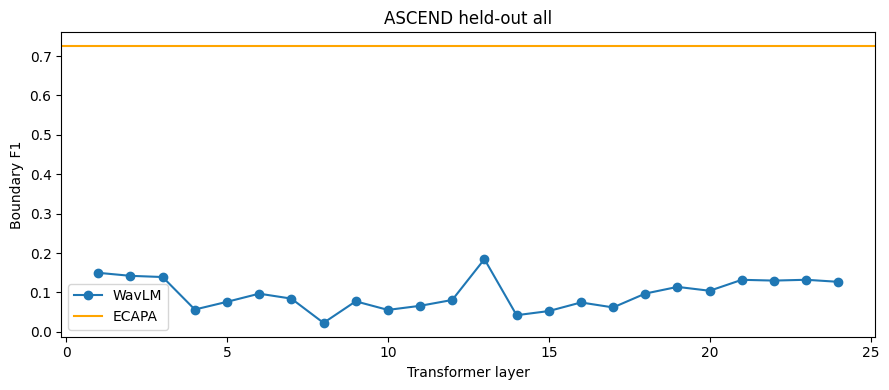

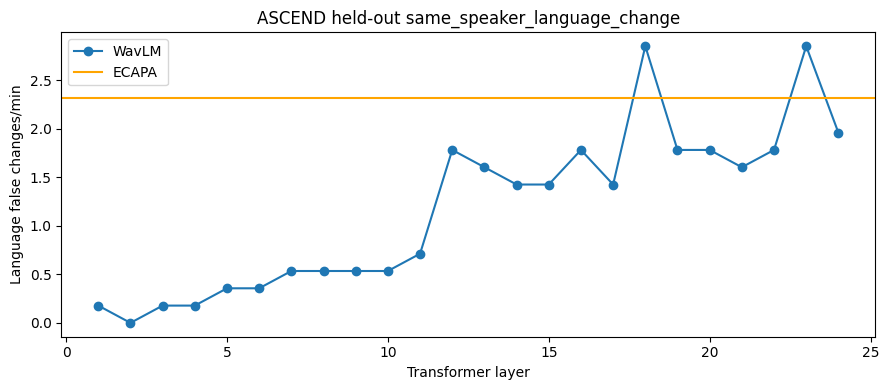

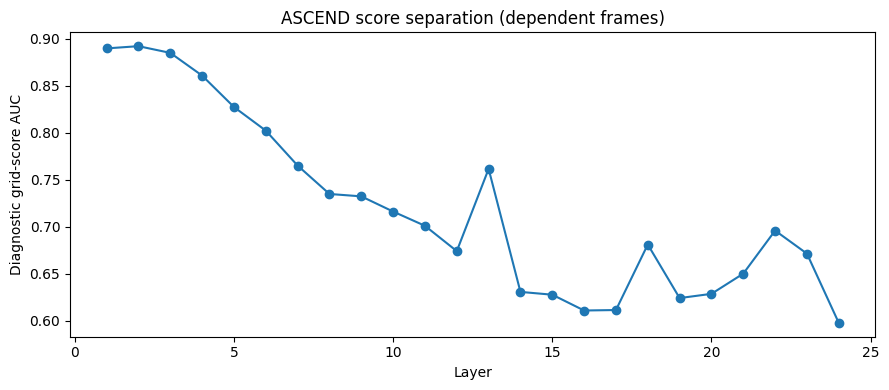

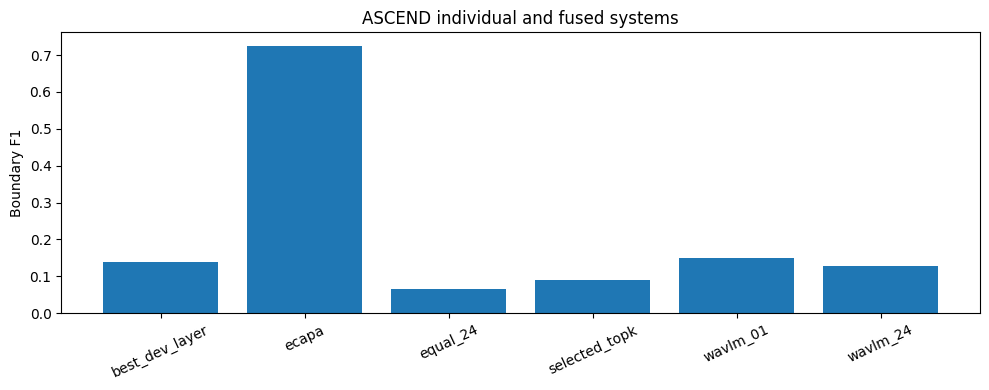

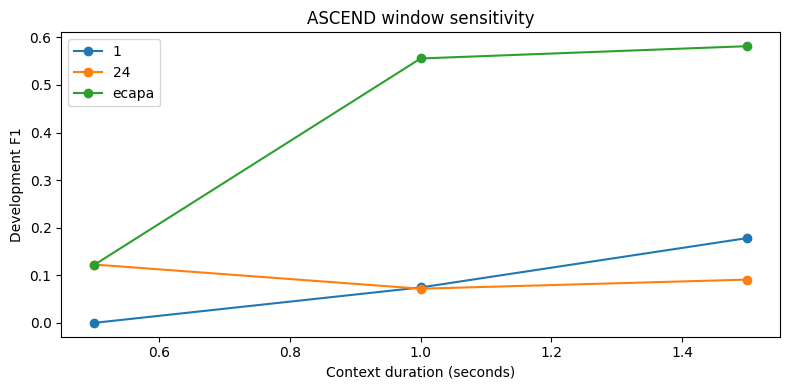

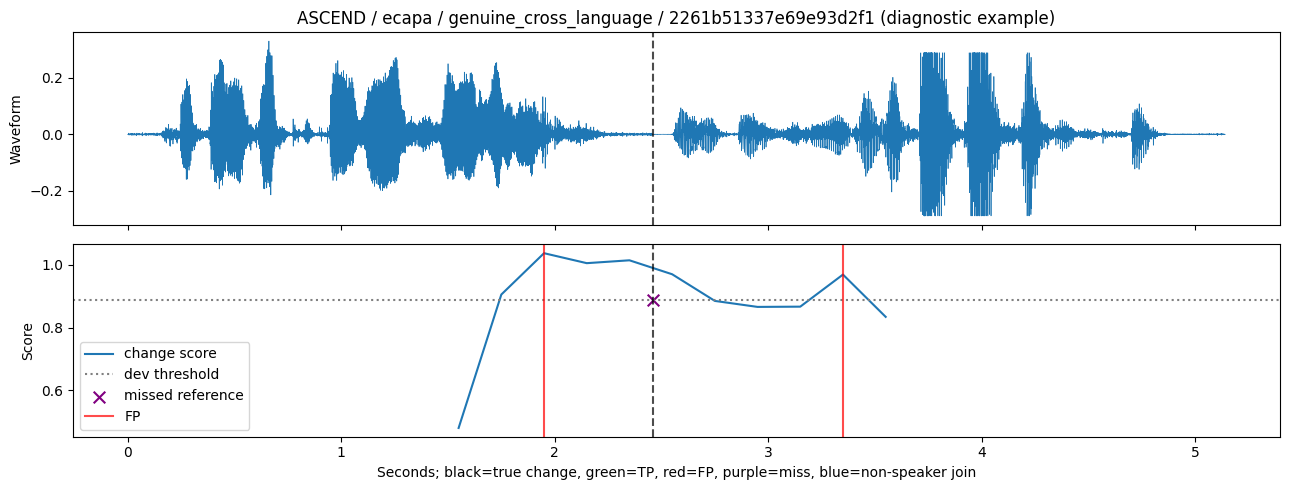

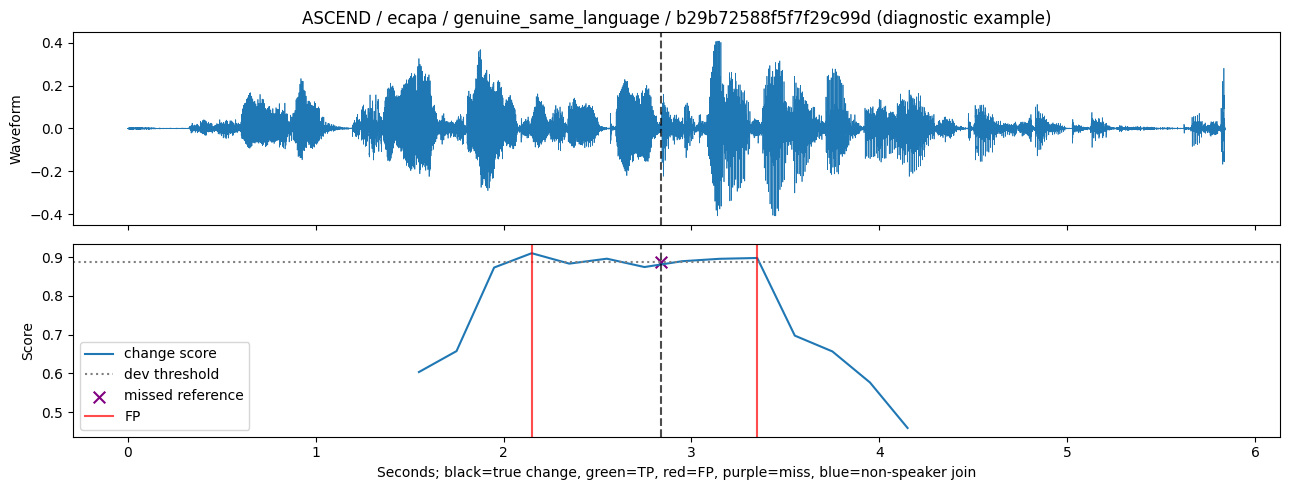

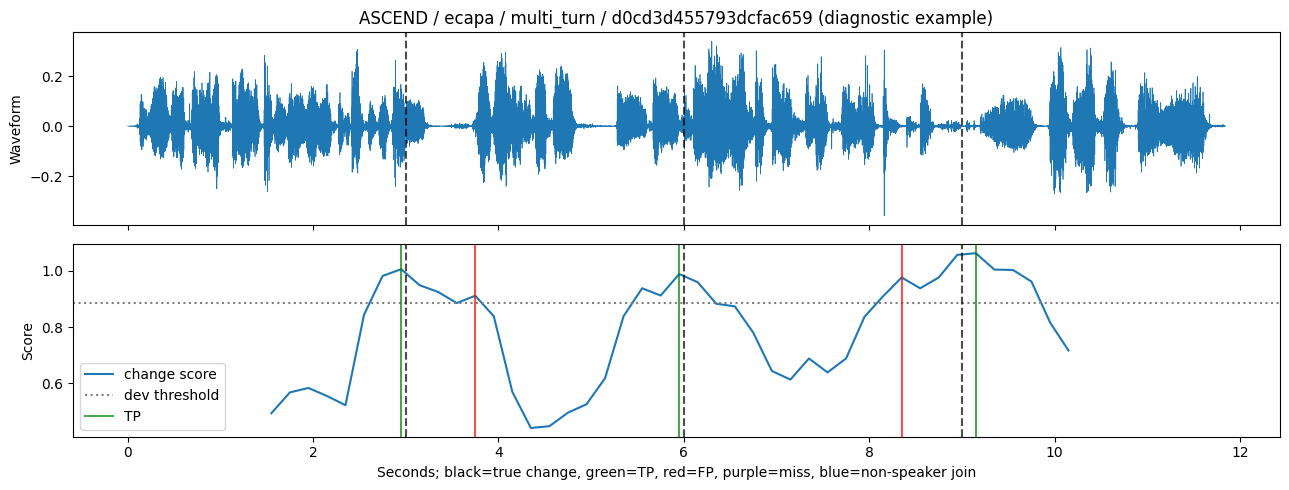

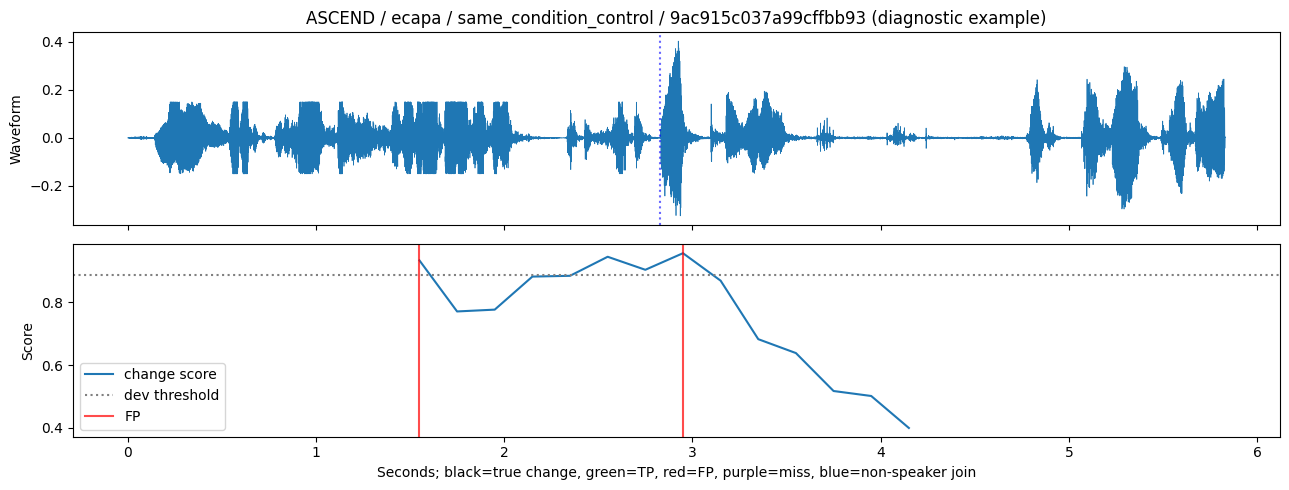

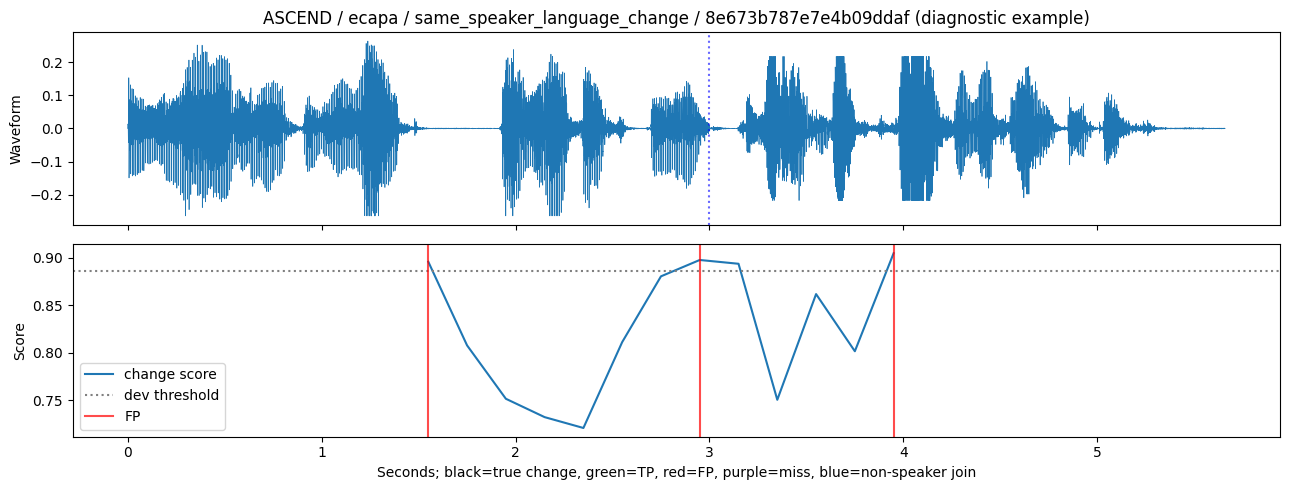

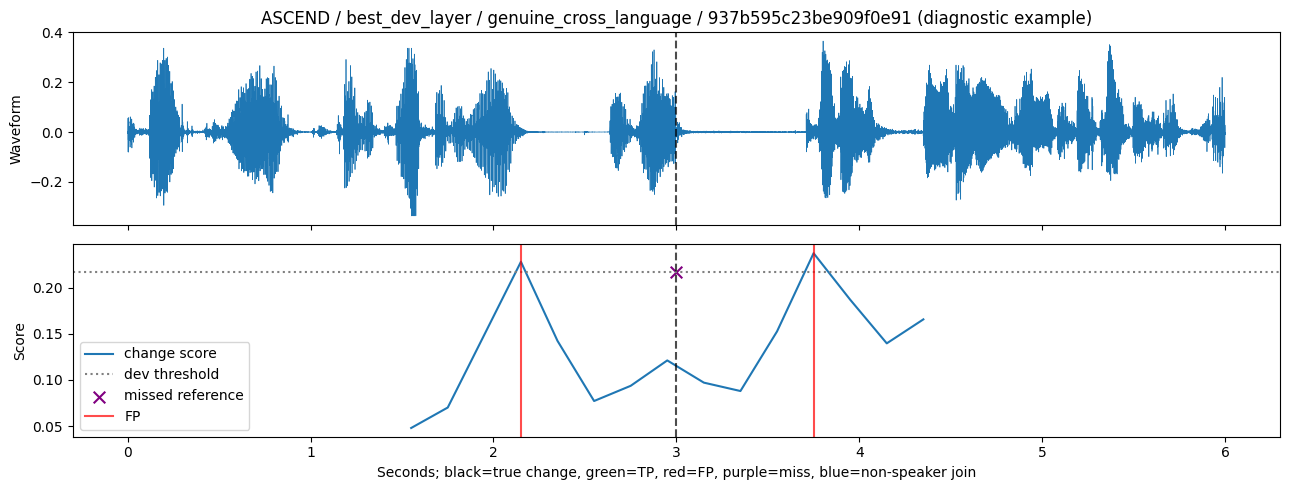

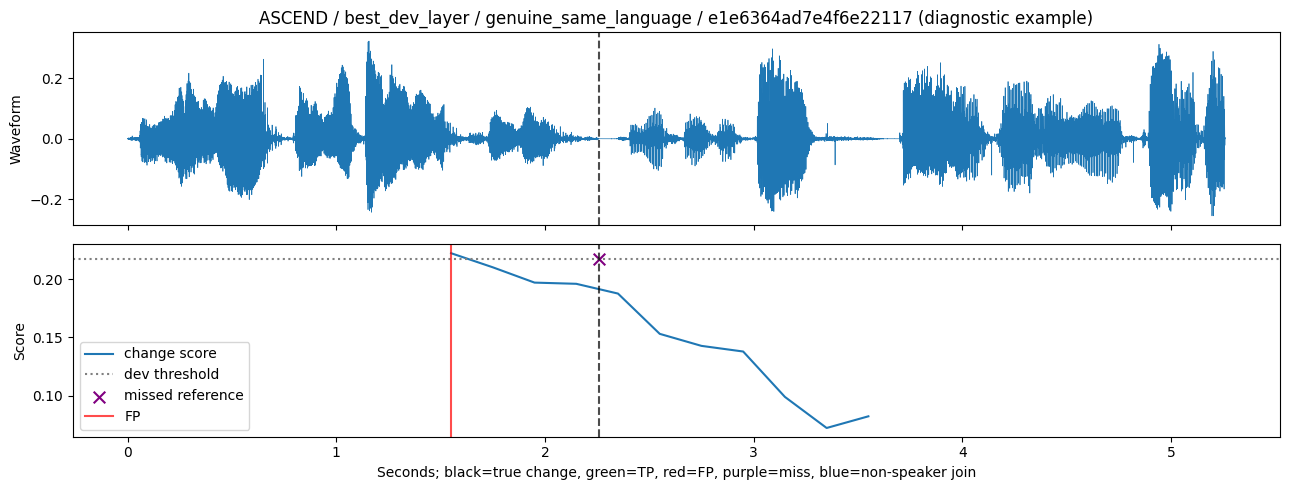

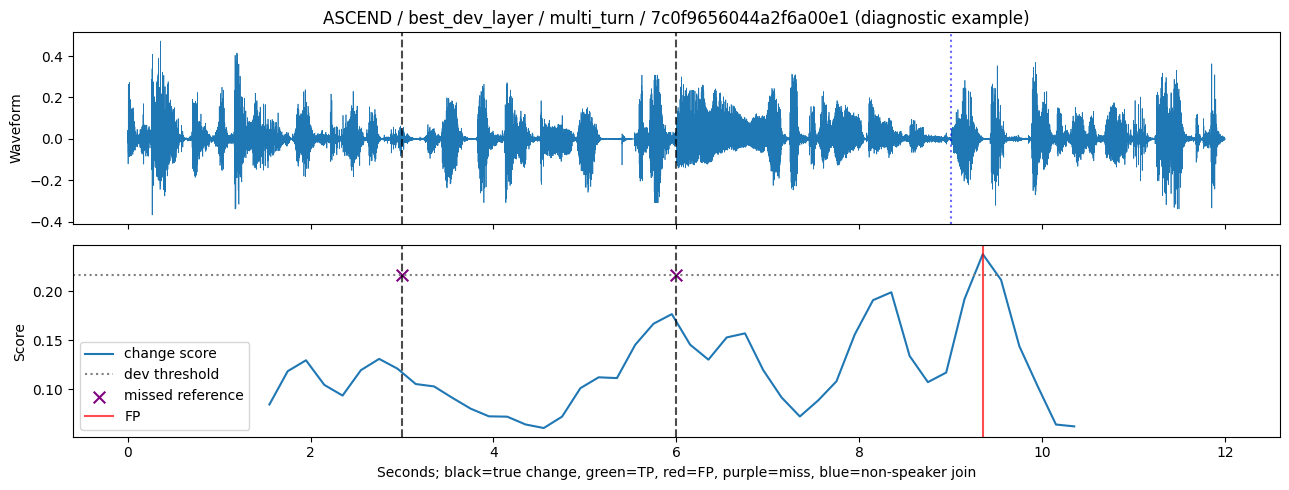

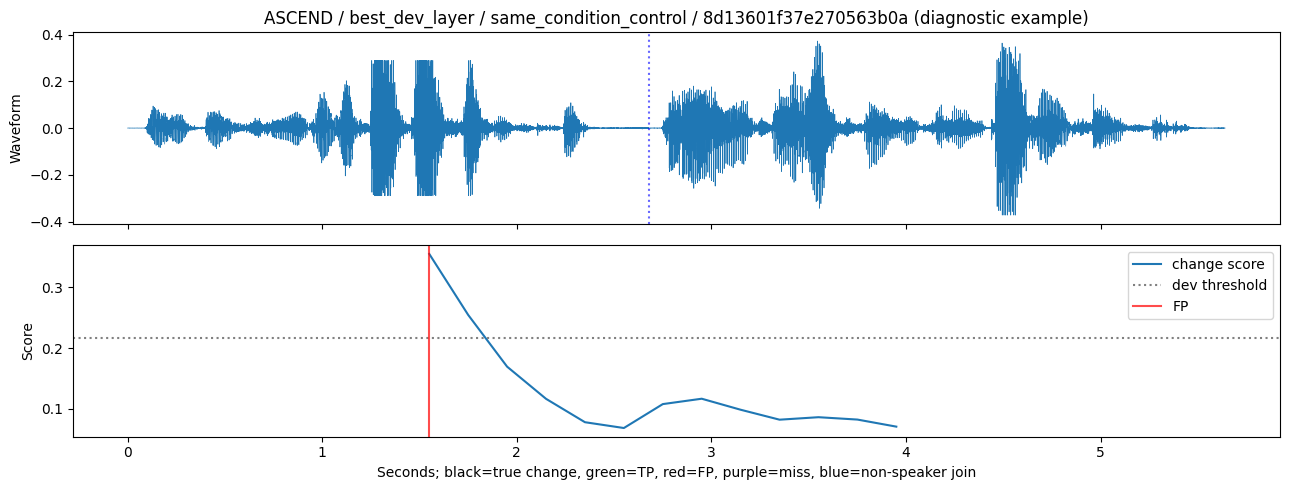

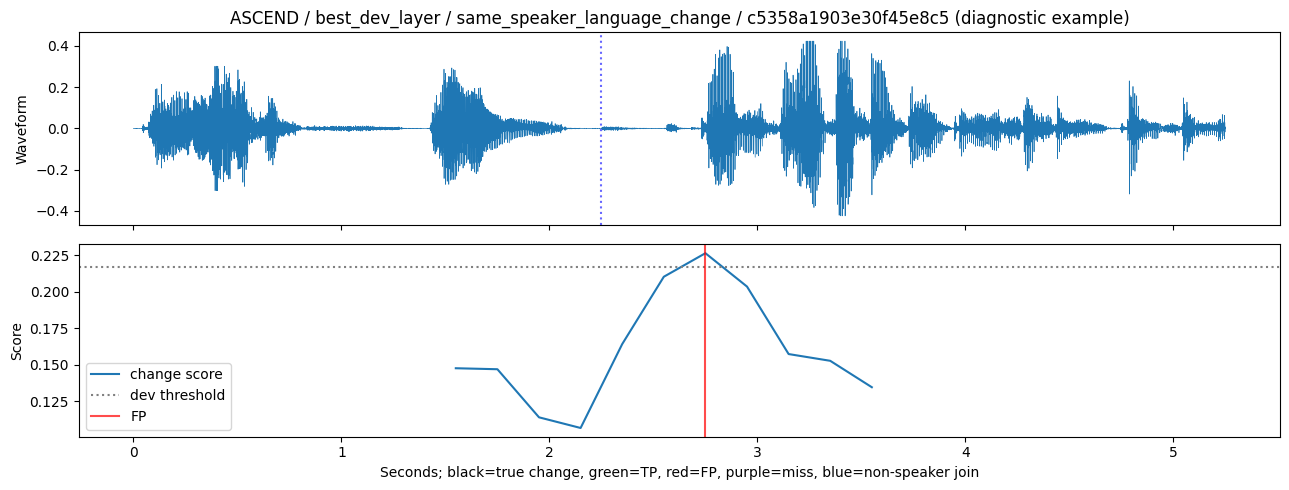

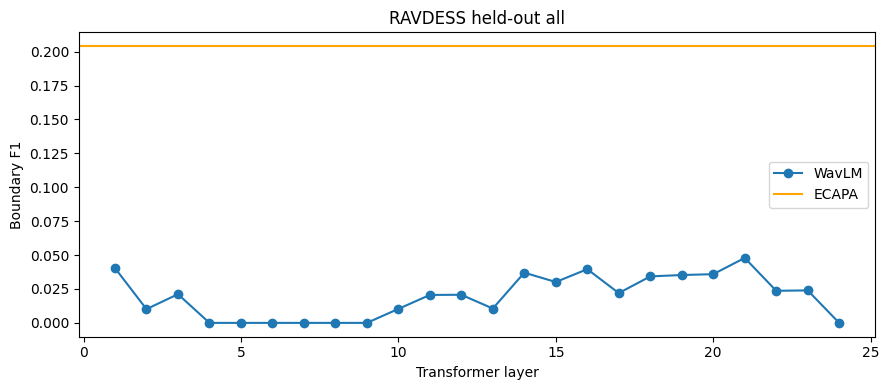

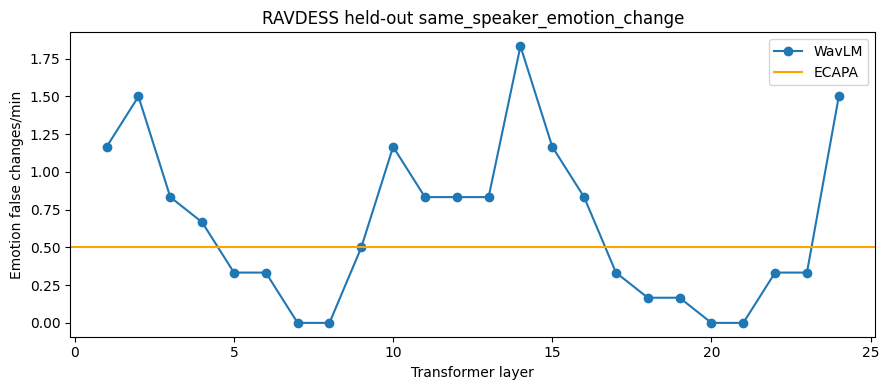

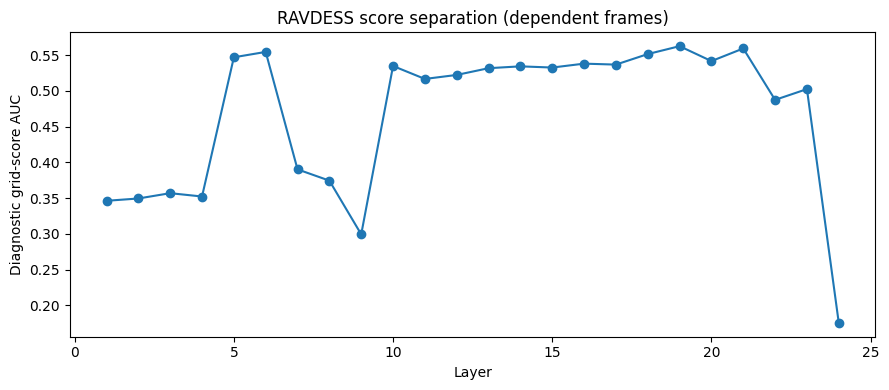

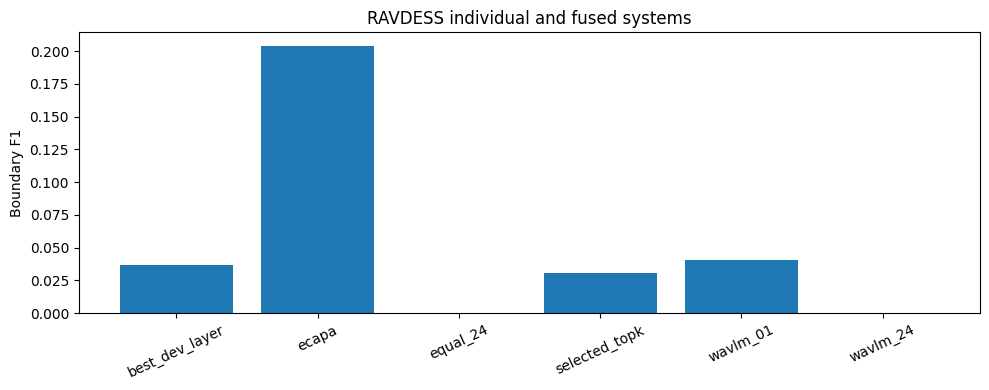

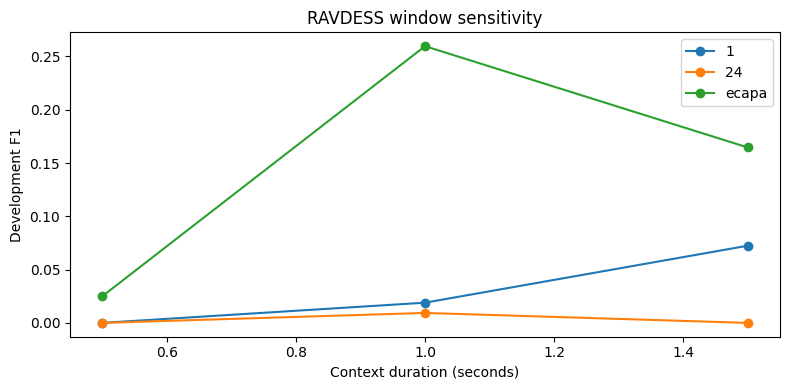

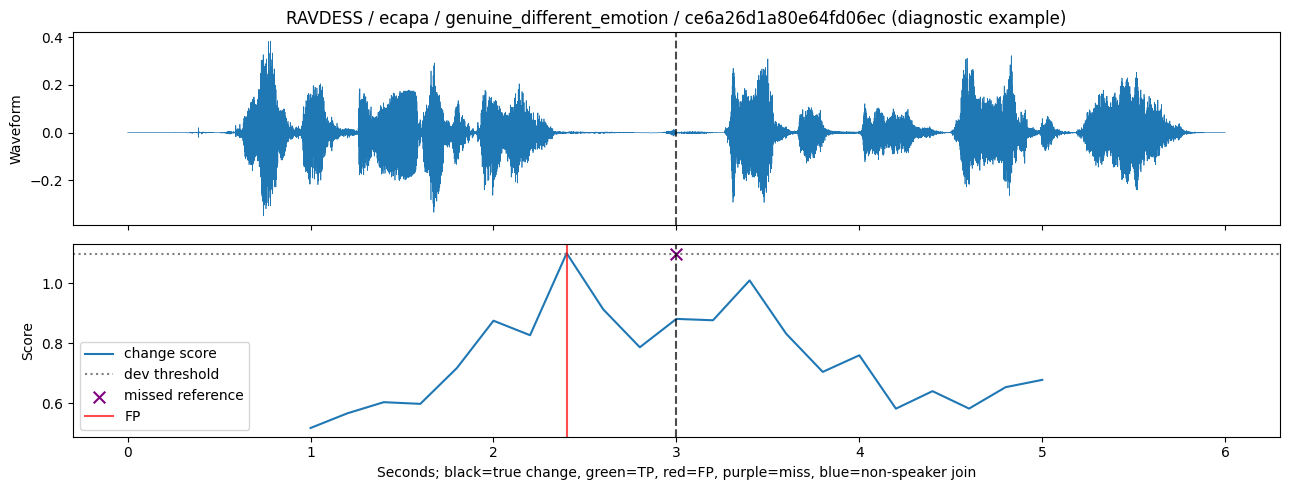

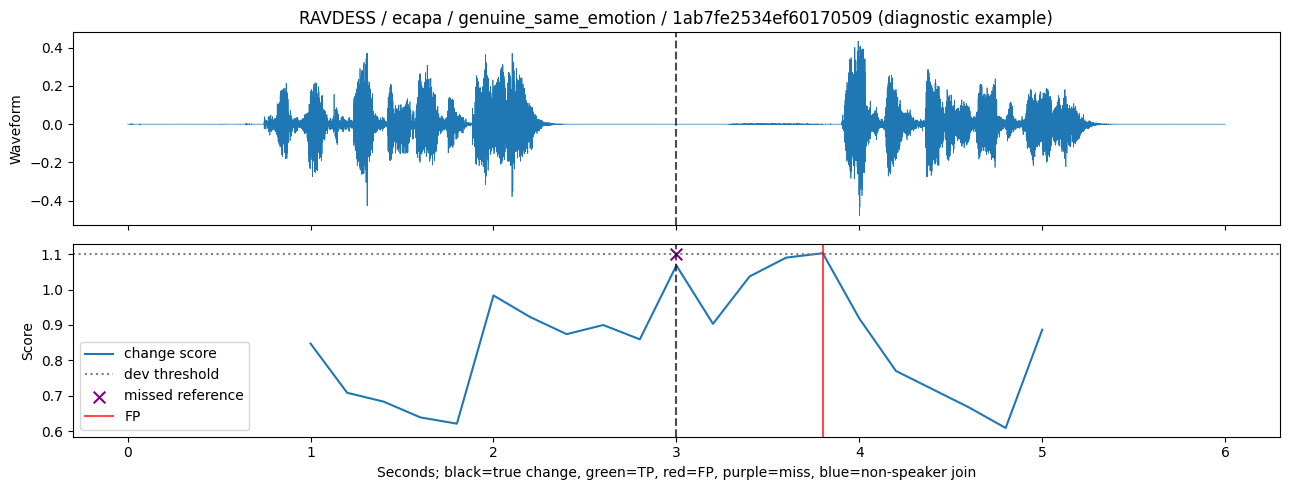

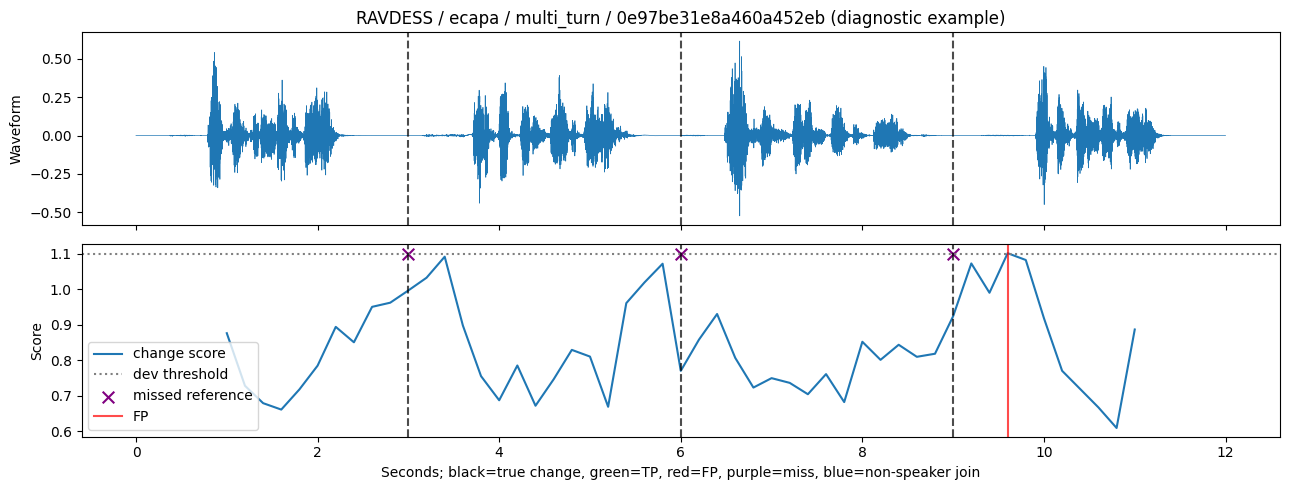

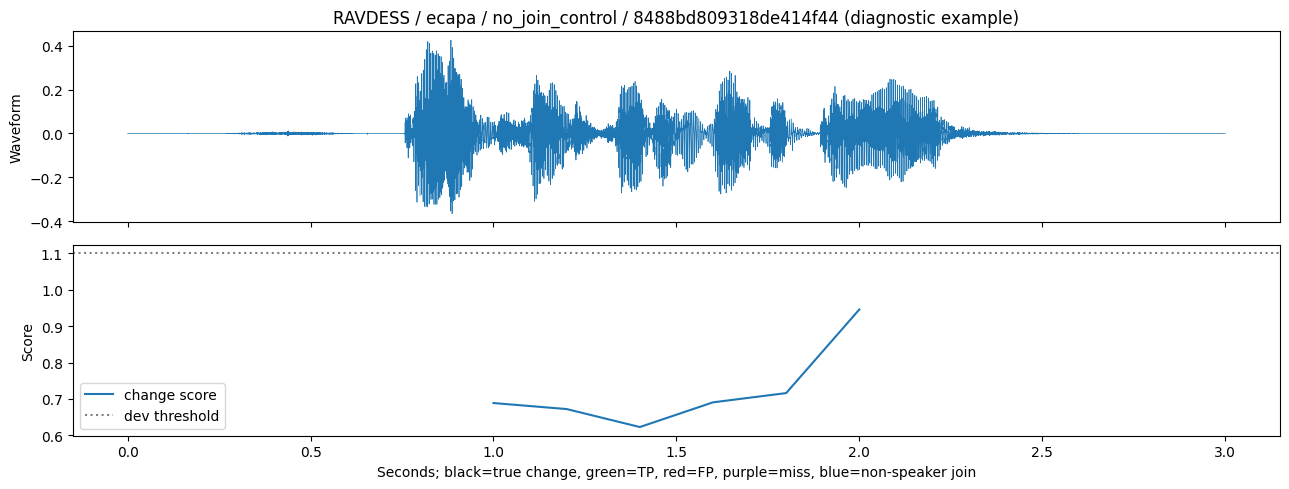

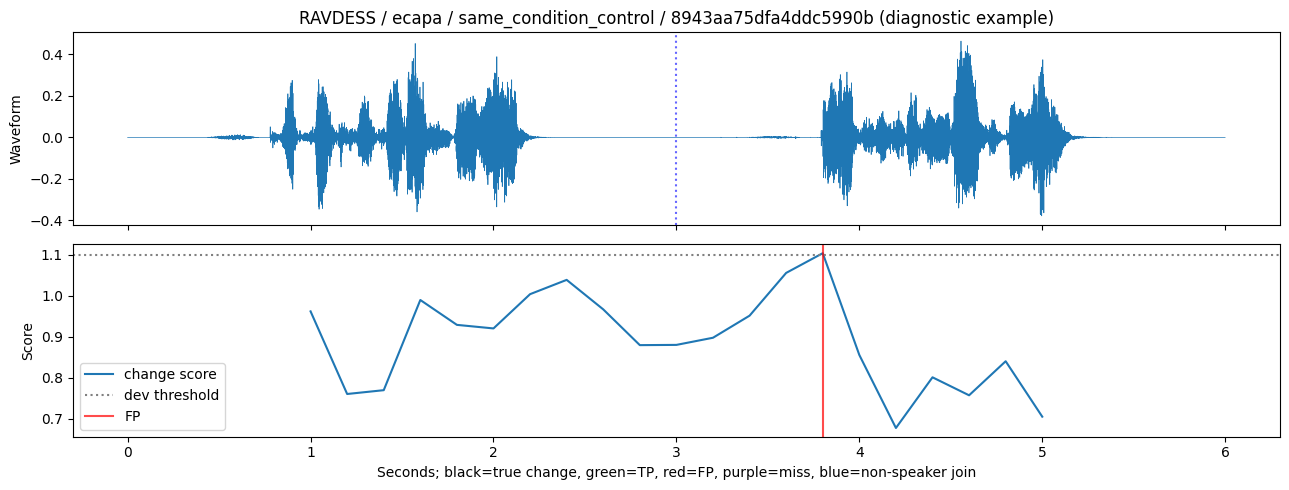

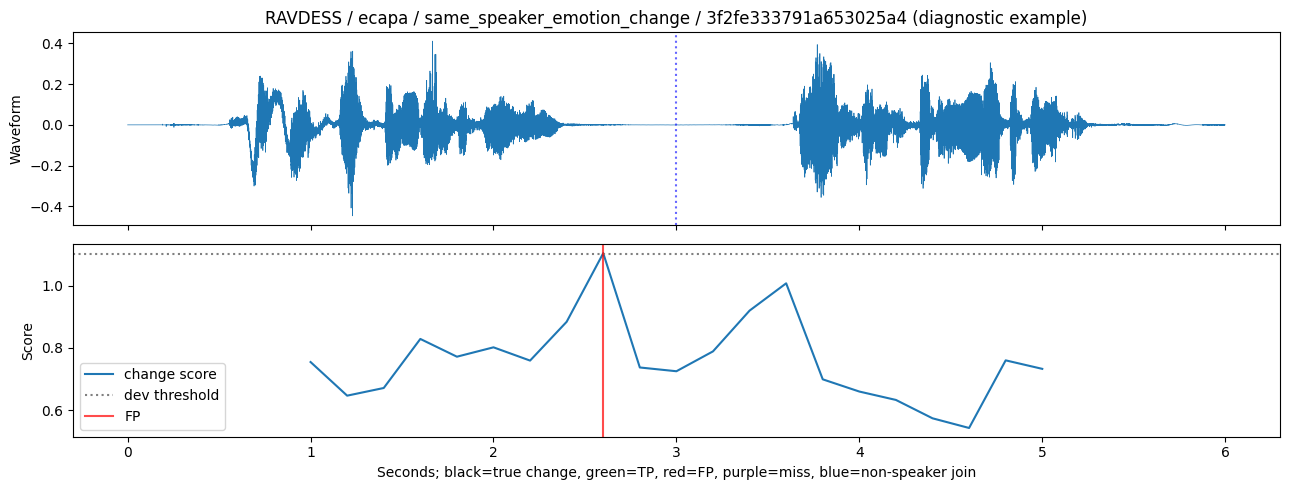

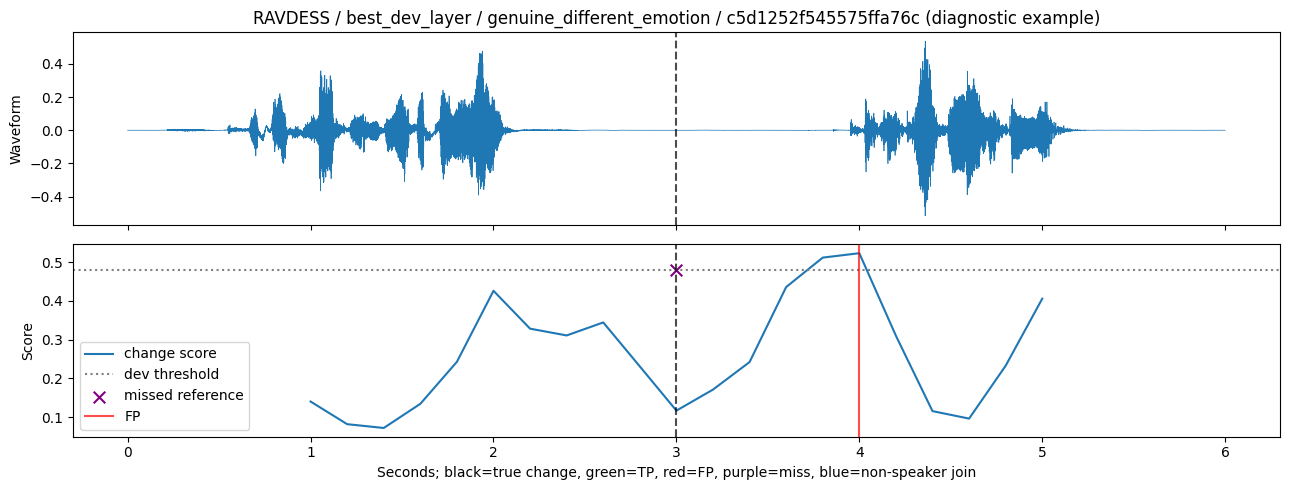

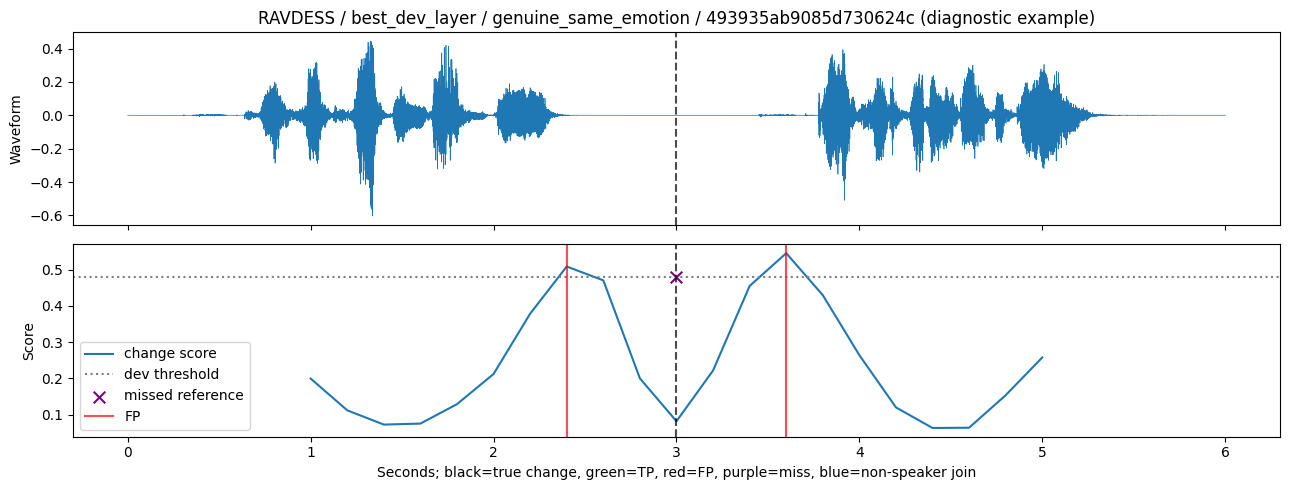

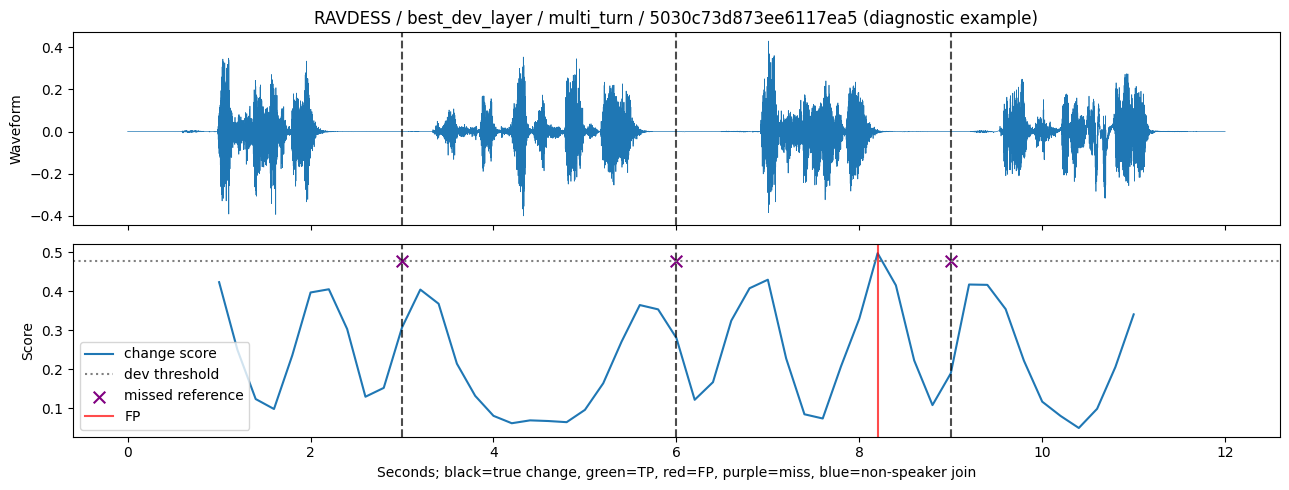

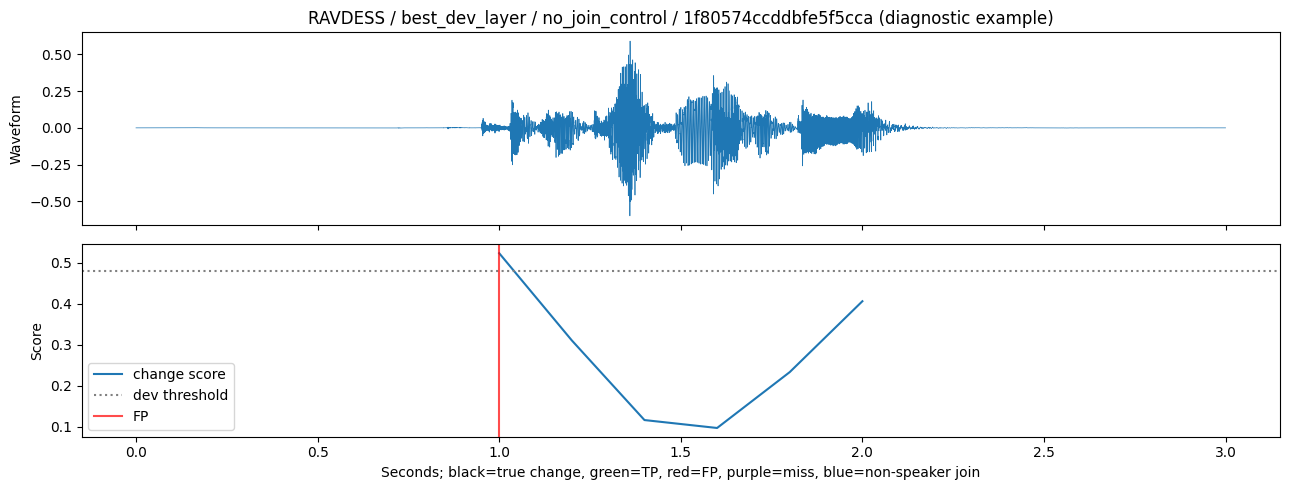

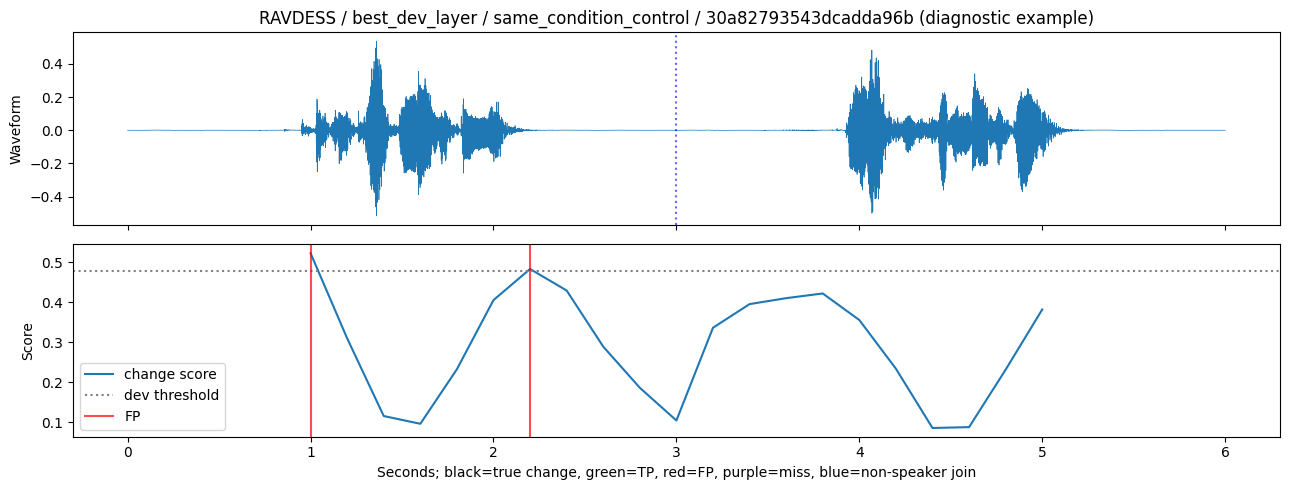

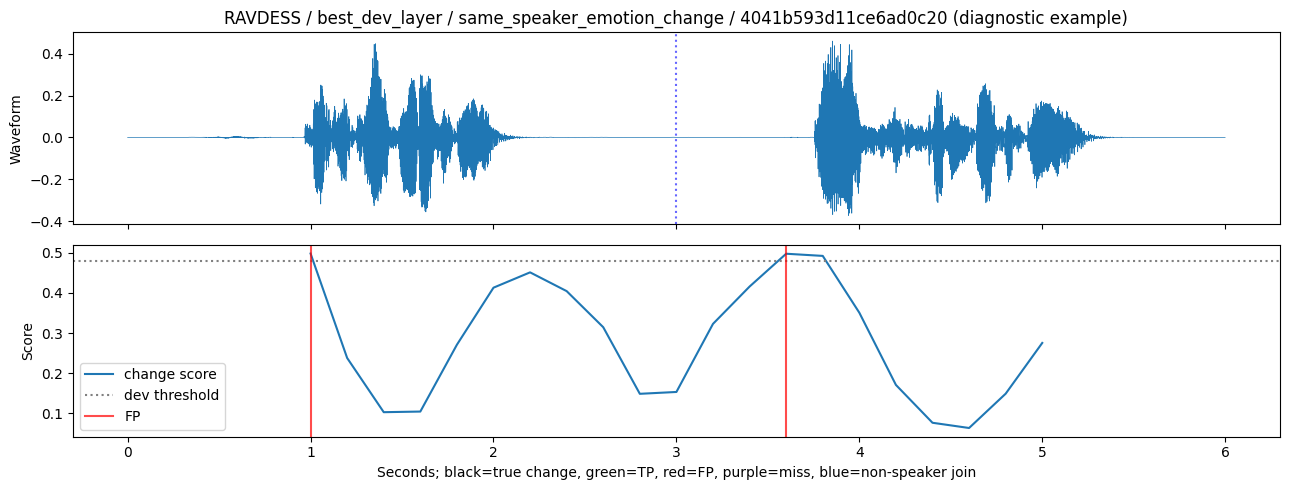

In [15]:
FIGURES=[]
def finish_figure(name):
    path=OUT/'figures'/name; plt.tight_layout(); plt.savefig(path,dpi=150,bbox_inches='tight'); FIGURES.append('figures/'+name); plt.show(); plt.close()
for ds in seqs.dataset.unique():
    lm=metrics[(metrics.dataset==ds)&metrics.system.str.match(r'wavlm_\d+')&(metrics.tolerance==CFG['selection_tolerance'])].copy()
    if lm.empty: continue
    lm['layer']=lm.system.str.extract(r'(\d+)').astype(int)
    for group,col,title in [('all','f1','Boundary F1'),('same_speaker_language_change','fa_per_min','Language false changes/min'),('same_speaker_emotion_change','fa_per_min','Emotion false changes/min')]:
        g=lm[lm.group==group].sort_values('layer')
        if g.empty: continue
        plt.figure(figsize=(9,4)); plt.plot(g.layer,g[col],'o-',label='WavLM')
        ec=metrics[(metrics.dataset==ds)&(metrics.system=='ecapa')&(metrics.group==group)&(metrics.tolerance==CFG['selection_tolerance'])]
        if len(ec) and np.isfinite(ec.iloc[0][col]): plt.axhline(ec.iloc[0][col],color='orange',label='ECAPA')
        plt.xlabel('Transformer layer'); plt.ylabel(title); plt.title(ds+' held-out '+group); plt.legend(); finish_figure(ds+'_'+group+'_'+col+'.png')
    g=separation[(separation.dataset==ds)&separation.system.str.match(r'wavlm_\d+')].copy()
    if len(g):
        g['layer']=g.system.str.extract(r'(\d+)').astype(int); g=g.sort_values('layer')
        plt.figure(figsize=(9,4)); plt.plot(g.layer,g.score_auc,'o-'); plt.xlabel('Layer'); plt.ylabel('Diagnostic grid-score AUC'); plt.title(ds+' score separation (dependent frames)'); finish_figure(ds+'_separation.png')
    g=comparison[(comparison.dataset==ds)&(comparison.group=='all')&(comparison.tolerance==CFG['selection_tolerance'])]
    if len(g):
        plt.figure(figsize=(10,4)); plt.bar(g.system,g.f1); plt.xticks(rotation=25); plt.ylabel('Boundary F1'); plt.title(ds+' individual and fused systems'); finish_figure(ds+'_systems.png')
    ab=pd.DataFrame(ABLATIONS); ab=ab[(ab.dataset==ds)&ab.system.isin(['1','24','ecapa'])]
    if len(ab):
        plt.figure(figsize=(8,4))
        for name,h in ab.groupby('system'): plt.plot(h.context,h.dev_f1,'o-',label=name)
        plt.xlabel('Context duration (seconds)'); plt.ylabel('Development F1'); plt.title(ds+' window sensitivity'); plt.legend(); finish_figure(ds+'_window_ablation.png')
    chosen=[r for r in SELECTED if r['dataset']==ds and r['reported_system'] in ['ecapa','best_dev_layer']]
    for spec in chosen:
        system=spec['reported_system']; ev=evaluation[(evaluation.dataset==ds)&(evaluation.system==system)&(evaluation.tolerance==CFG['selection_tolerance'])]
        if ev.empty: continue
        candidates=[]
        for group,h in ev.groupby('group'):
            candidates.append(h.sort_values(['fp','fn'],ascending=False).iloc[0].sequence)
        for sid in candidates:
            s=seqs[seqs.sequence==sid].iloc[0].to_dict(); item=get_signal(s,spec)
            if item is None: continue
            t,x=item; y,sr=sf.read(s['path'],dtype='float32'); pp=predict(t,x,spec['threshold']); jj=joins[(joins.sequence==sid)&joins.is_change]; rr=jj.time.to_numpy()
            pairs,fp,fn=match_boundaries(pp,rr,CFG['selection_tolerance']); tp={i for i,j,e in pairs}
            fig,axes=plt.subplots(2,1,figsize=(13,5),sharex=True); stride=max(1,len(y)//20000)
            axes[0].plot(np.arange(0,len(y),stride)/sr,y[::stride],linewidth=.5); axes[0].set_ylabel('Waveform')
            axes[1].plot(t,x,label='change score'); axes[1].axhline(spec['threshold'],color='gray',ls=':',label='dev threshold')
            for k,v in enumerate(rr):
                for ax in axes: ax.axvline(v,color='black',ls='--',alpha=.7)
                if k in fn: axes[1].scatter([v],[spec['threshold']],marker='x',color='purple',s=70,label='missed reference' if k==fn[0] else None)
            for i,v in enumerate(pp): axes[1].axvline(v,color='green' if i in tp else 'red',alpha=.7,label=('TP' if i in tp else 'FP') if i==0 else None)
            for v in joins[(joins.sequence==sid)&(~joins.is_change)].time: axes[0].axvline(v,color='blue',ls=':',alpha=.6)
            axes[1].set_xlabel('Seconds; black=true change, green=TP, red=FP, purple=miss, blue=non-speaker join'); axes[1].set_ylabel('Score'); axes[1].legend()
            axes[0].set_title(f'{ds} / {system} / {s["group"]} / {sid} (diagnostic example)'); finish_figure(ds+'_'+system+'_'+sid+'.png')
save_json(OUT/'figures_manifest.json',FIGURES)


## Results and exports

Save summary tables, figures, and the final experiment report.


In [16]:
def md(table): return table.to_markdown(index=False) if not table.empty else 'Unavailable: no supported observations or selected systems.'
lines=['# Experiment 4: Robust Speaker-Change Detection', '\nRun status: '+('SMOKE TEST — functionality check only, not final experimental evidence.' if SMOKE_TEST else 'Configured full sampled experiment; interpret within reported coverage.'), '\n## Objectives and motivation', 'Test whether frozen representations distinguish identity changes from same-speaker language/emotion variation. H1–H4 are hypotheses, not premises. Mitra et al. (2025), Modeling Speech Emotion with Label Variance and Analyzing Performance Across Speakers and Unseen Acoustic Conditions (https://arxiv.org/pdf/2503.22711), motivates intermediate-layer selection and speaker-level analysis; emotion recognition results do not establish boundary detection results.', '\n## Relationship to Experiments 1–3', 'Experiments 1–2 explored layer-dependent speaker information and emotion variation; their numerical results are unavailable. Experiment 3 was utterance verification, not boundary detection. Historical supplied metrics only: ECAPA same-language/cross-language EER 16.67%/12.67%, cross-language AUC .9094; WavLM layer 1 23.33%/29.33%, .7655; layer 24 36%/41.33%, .6070. Five held-out speakers limit those historical findings. No historical value is included in Experiment 4 tables.', '\n## Dataset details, feasibility and exclusions', md(summary), '\nUsable recordings by dataset and split:', md(records.groupby(['dataset','split']).agg(recordings=('recording','nunique'),speakers=('speaker','nunique'),seconds=('duration','sum')).reset_index()), '\nPer-speaker condition eligibility:', md(eligibility), '\nDiagnostics:', '\n'.join('- '+s for s in DIAGNOSTICS) or 'No recorded warnings.', '\n## Synthetic speech and controls', 'Sequences were sampled after independent speaker partitions. Exact canonical duplicate audio cannot cross partitions. Crops, RMS normalization, edge fades and joining gaps are identical for positive/negative joins. Same-condition joins and uninterrupted utterances control for discontinuities. Sessions/microphones/backgrounds are not controlled; silence and gain processing can introduce artifacts. No-join controls rely on source speaker annotation. Mixed ASCEND clips are audited but excluded from controlled language pairs.', md(seqs.groupby(['dataset','split','group']).size().rename('sequences').reset_index()), '\n## Detection and selection', 'Fixed-grid adjacent-window cosine distances, audio-only peaks, time-based nonmaximum suppression. All 24 frozen WavLM transformer layers (not hidden_states[0]) and pretrained normalized ECAPA embeddings. Valid-frame mean pooling. One-to-one tolerance matching maximizes valid match count and minimizes localization error. Development-only threshold/context/layer selection subject to negative-sequence false-alarm target. Train-only robust score scaling; equal-24 and development-selected top-k fusion where supported. Test data is evaluated after selections freeze.', '\nFrozen configurations and achieved development operating points:', md(pd.DataFrame(SELECTED)), '\n## Quantitative comparisons: WavLM, ECAPA and fusion']
for ds in seqs.dataset.unique():
    lines.extend(['\n### '+ds,md(comparison[comparison.dataset==ds]),'\nIndividual WavLM layers:',md(metrics[(metrics.dataset==ds)&metrics.system.str.match(r'wavlm_\d+')&(metrics.group=='all')])])
lines.extend(['\n## Language robustness', md(comparison[comparison.group.isin(['genuine_same_language','genuine_cross_language','same_speaker_language_change','same_condition_control','no_join_control'])]), '\n## Emotion robustness', md(comparison[(comparison.dataset=='RAVDESS')&comparison.group.isin(['genuine_same_emotion','genuine_different_emotion','same_speaker_emotion_change','same_condition_control','no_join_control'])]), '\n## Speaker-level generalization', md(per_speaker), '\nSpeaker-node sensitivity intervals:', md(intervals), '\n## Quantitative interpretation and conclusions'])
for ds in seqs.dataset.unique():
    selected=[r for r in SELECTED if r['dataset']==ds and r['reported_system']=='best_dev_layer']
    if selected: lines.append(f'{ds}: development selected transformer layer {selected[0]["layers"][0]} with context {selected[0]["context"]} s; selection does not imply universal optimality.')
    g=comparison[(comparison.dataset==ds)&(comparison.group=='all')&(comparison.tolerance==CFG['selection_tolerance'])]
    for r in g.itertuples(): lines.append(f'{ds}, {r.system}: computed held-out F1={r.f1:.4f}; false alarms/min={r.fa_per_min:.4f}; localization MAE={r.localization_mae:.4f} s.')
lines.extend(['No hypothesis is automatically accepted from ranking alone. Compare condition-specific false alarms, uncertainty, sample support, final-layer and ECAPA baselines. A small language score shift alone is not identity discrimination; utterance verification and continuous boundary detection need not rank layers alike.', '\n## Figures', '\n'.join(f'![{p}]({p})' for p in FIGURES) or 'No supported figures.', '\n## Statistical limitations', 'Small speaker populations, reused recordings and synthetic pairs induce dependence. Speaker-node Bayesian bootstrap intervals are descriptive graph sensitivity intervals, not independent-sequence confidence intervals or significance tests. Test-derived score AUC is a correlated-frame diagnostic. Caps and bounded pair sampling limit coverage; original corpus splits are not assumed speaker-disjoint. Exact hashing cannot exclude near duplicates or shared acoustic content. No controlled microphone/session matching; cropped utterances may contain unannotated events. Synthetic joins cannot establish performance on naturally occurring conversations. Smoke runs cannot support final claims.', '\n## Remaining accent-variation work', 'Neither dataset controls the same speaker deliberately changing accent. Chinese versus English is language variation, not an accent contrast. No accent labels were manufactured and accent robustness remains untested. A future dataset can reuse the speaker/condition/sequence interfaces with explicit accent metadata.', '\n## Future natural-conversation evaluation', 'Validate on independently annotated natural conversations with overlap, turn-taking, realistic silence, channel variation and broader speaker populations. Freeze the full pipeline before external evaluation. Expand speakers and stimuli before inferential claims.', '\n## Reproducibility', 'See config.json, environment.json, speaker_partitions.csv, sequence_metadata.csv, sequence_segments.csv, ground_truth_boundaries.csv (all joins, is_change flag), diagnostics.json and immutable model revisions. Requested tables, embeddings, sequences and figures are colocated in this run directory.'])
(OUT/'experiment4_report.md').write_text('\n\n'.join(lines))
print('Report:',OUT/'experiment4_report.md')
print('Mode:', 'SMOKE — not final' if SMOKE_TEST else 'FULL configured workload')
print('Saved requested outputs:', [p.name for p in OUT.iterdir() if p.name in ['config.json','environment.json','dataset_audit.csv','speaker_partitions.csv','sequence_metadata.csv','ground_truth_boundaries.csv','predictions.csv','layer_metrics.csv','model_comparison.csv','per_speaker_metrics.csv','ablation_results.csv','embeddings','sequences','figures','experiment4_report.md']])


Report: /content/drive/MyDrive/Experiment_4_Results/full/cf61e798b8ae007742d4/experiment4_report.md
Mode: FULL configured workload
Saved requested outputs: ['embeddings', 'sequences', 'figures', 'config.json', 'environment.json', 'dataset_audit.csv', 'speaker_partitions.csv', 'sequence_metadata.csv', 'ground_truth_boundaries.csv', 'ablation_results.csv', 'predictions.csv', 'layer_metrics.csv', 'model_comparison.csv', 'per_speaker_metrics.csv', 'experiment4_report.md']
